# EXPEDIA — Báo cáo hiểu sâu dữ liệu

**Phạm vi: EDA trên dữ liệu gốc; chưa feature engineering, chưa huấn luyện mô hình.**

Báo cáo có từ điển dữ liệu, kiểm tra chất lượng/khóa/nhãn, thống kê theo nhóm, thời gian và giới hạn suy rộng. Các kết quả được tính lại từ CSV; bản đọc nhanh nằm ở `reports/EXPEDIA/README.md`.

Mọi phân nhóm tạm thời chỉ phục vụ mô tả, không tạo tập feature. Chạy tất cả các cell theo thứ tự; cell đầu quét dữ liệu đầy đủ nên có thể mất vài phút với Expedia. Phần tóm tắt điều hành nằm đầu; bảng kiểm kê dài chuyển sang phụ lục. Mỗi hình có nhận xét riêng ngay bên dưới.

In [1]:
from pathlib import Path
import importlib
import sys

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / 'data' / 'raw').is_dir():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise FileNotFoundError('Không tìm thấy data/raw; hãy mở notebook trong dự án Propensity.')
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from scripts import build_descriptive_reports as eda
importlib.reload(eda)
report = eda.build_report('EXPEDIA', PROJECT_ROOT)
print('Đã tính lại từ CSV raw; số chính:', report.facts)
print('Chỉ xuất báo cáo, metadata và biểu đồ; không tạo dữ liệu mô hình.')

train.csv: 250,000 rows
train.csv: 500,000 rows
train.csv: 750,000 rows
train.csv: 1,000,000 rows
train.csv: 1,250,000 rows
train.csv: 1,500,000 rows
train.csv: 1,750,000 rows
train.csv: 2,000,000 rows
train.csv: 2,250,000 rows
train.csv: 2,500,000 rows
train.csv: 2,750,000 rows
train.csv: 3,000,000 rows
train.csv: 3,250,000 rows
train.csv: 3,500,000 rows
train.csv: 3,750,000 rows
train.csv: 4,000,000 rows
train.csv: 4,250,000 rows
train.csv: 4,500,000 rows
train.csv: 4,750,000 rows
train.csv: 5,000,000 rows
train.csv: 5,250,000 rows
train.csv: 5,500,000 rows
train.csv: 5,750,000 rows
train.csv: 6,000,000 rows
train.csv: 6,250,000 rows
train.csv: 6,500,000 rows
train.csv: 6,750,000 rows
train.csv: 7,000,000 rows
train.csv: 7,250,000 rows
train.csv: 7,500,000 rows
train.csv: 7,750,000 rows
train.csv: 8,000,000 rows
train.csv: 8,250,000 rows
train.csv: 8,500,000 rows
train.csv: 8,750,000 rows
train.csv: 9,000,000 rows
train.csv: 9,250,000 rows
train.csv: 9,500,000 rows
train.csv: 9,750,0

## Thuật ngữ và cách đọc báo cáo

In [2]:
eda.show_section(report, 'glossary')

Quy ước số: dấu chấm là phần thập phân; dấu phẩy phân tách hàng nghìn. Tên cột và mã giá trị gốc được giữ trong bảng để đối chiếu CSV. Mọi chỉ số mô hình ở mục 7 là tiêu chí đề xuất, chưa được đo.

**Thuật ngữ**

| Thuật ngữ | Cách hiểu trong báo cáo |
| --- | --- |
| Propensity | Xác suất thực hiện hành vi trong quần thể và thời hạn đã định; không phải tác động của chiến dịch. |
| t0 | Thời điểm chấm điểm; mọi đầu vào và trạng thái thiếu của chúng phải được biết tại thời điểm này. |
| Rò rỉ nhãn | Dùng thông tin chỉ có sau hành vi cần dự đoán làm đầu vào. |
| Nhãn hoàn tất | Kết quả đã được ghi nhận và sẵn có trước mốc học hoặc hiệu chỉnh. |
| Nhóm theo thời gian | Các booking/search cùng giai đoạn; thay đổi cơ cấu có thể làm đổi tỷ lệ nhãn. |
| Cramér V | Độ mạnh liên hệ giữa nhóm và nhãn, từ 0 đến 1; không chứng minh nhân quả. |
| OOF theo thời gian | Điểm ngoài tập học tạo bằng mô hình chỉ dùng lịch sử sẵn có trước quan sát đó. |
| Hiệu chỉnh xác suất | Kiểm tra và điều chỉnh để điểm xác suất phù hợp với tần suất thực tế. |
| AP / log loss / Brier | AP đánh giá phân hạng nhị phân; log loss và Brier đánh giá dự đoán xác suất, càng thấp càng tốt. |
| Search–property | Một khách sạn trong một lượt tìm kiếm; nhiều dòng dùng chung srch_id. |
| NDCG@5 | Chất lượng thứ tự năm kết quả đầu, tính riêng mỗi search rồi lấy trung bình. |
| Sai lệch vị trí | Kết quả ở trên thường được nhìn thấy nhiều hơn; click không chỉ phản ánh sở thích. |

## Tóm tắt điều hành

In [3]:
eda.show_section(report, 'executive')

1. **Đơn vị và quy mô:** 9,917,530 cặp thuộc 399,344 search; 54 cột train và 50 cột test. Không có user ID để chấm CRM.

2. **Hai hành vi:** click 443,672 (4.47%), booking 276,593 (2.79%). Mẫu số là cặp search–property.

3. **Quần thể có điều kiện:** 0 search hoàn toàn không click trong train; không suy CTR/CVR toàn website từ mẫu này.

4. **Phụ thuộc trong search:** 0 search có cờ random không đồng nhất; đã tách trọng số theo dòng/search và phân tầng giá, sao theo cơ chế.

5. **Đầu vào và rò rỉ:** đủ 54 cột raw có quyết định; position, gross và hai nhãn bị chặn khỏi đầu vào trước hiển thị; srch_id chỉ làm khóa.

6. **Thiết kế đề xuất:** LR có tương tác so với LightGBM binary cho xác suất; LambdaRank là nhánh riêng. Giữ nguyên search qua các tập; khoảng đệm nhãn cần xác nhận, bootstrap theo search.

## 1. Bài toán và lý do chọn dữ liệu

In [4]:
eda.show_section(report, 'problem')

Đối tượng là khách sạn trong một search. Bài toán chính là P(booking | ngữ cảnh search và thuộc tính khách sạn trước hiển thị, thuộc quần thể đã chọn); click là mục tiêu phụ. Nhánh xếp hạng đánh giá thứ tự ứng viên theo từng search. Không có user ID và search không click nên chưa thể gọi đây là propensity CRM hoặc conversion toàn website. Không áp thời hạn 90 ngày của Airbnb cho hành vi trong search.

## 2. Tổng quan bộ dữ liệu

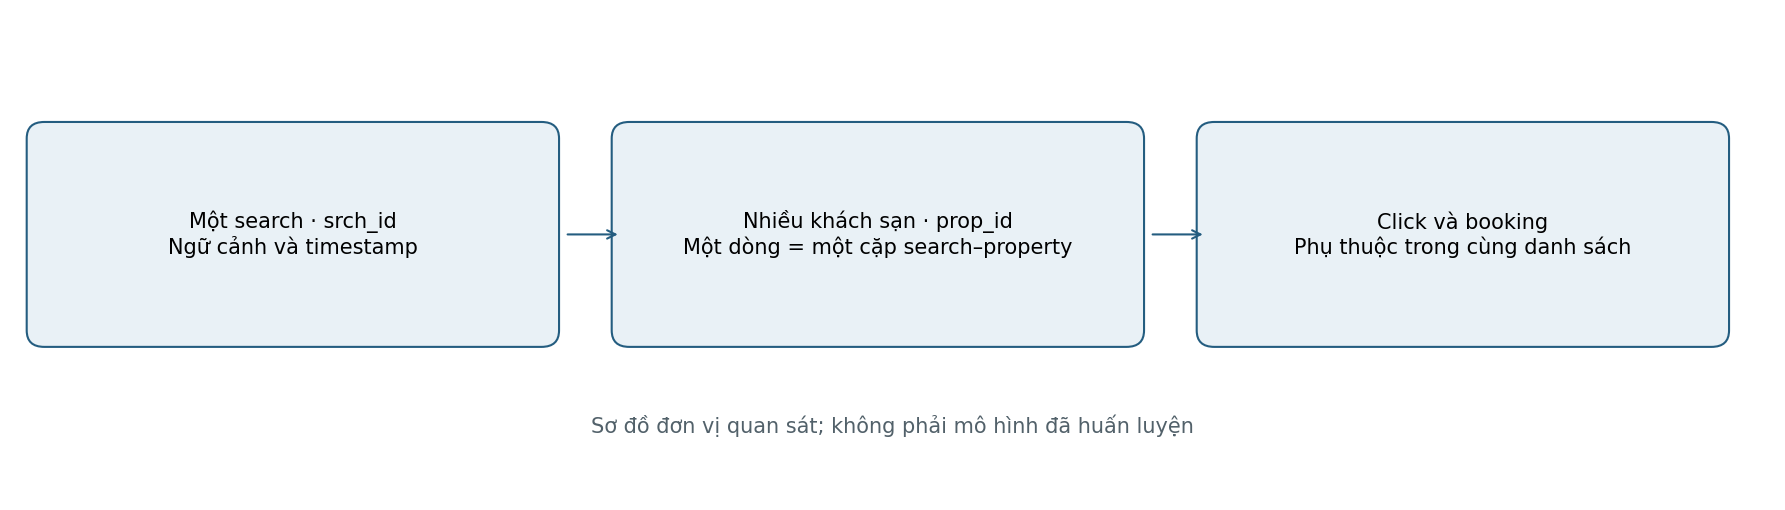

**Quan sát:** nhiều khách sạn cùng thuộc một search; số dòng không là số search hoặc số người dùng.

**Phạm vi và cách đọc:** sơ đồ cấu trúc dữ liệu raw hiện có, không biểu diễn quan hệ nhân quả.

### Nguồn gốc và phạm vi thu thập

Nguồn công bố: [trang dữ liệu/nghiên cứu gốc](https://www.kaggle.com/c/expedia-personalized-sort/data). [Giấy phép/điều khoản và trang phân phối](https://storage.googleapis.com/kaggle-media/competitions/kaggle/3504/media/Expedia%20Personalized%20Sort%20Official%20Competition%20Rules%20Final.pdf). Thông tin nào chưa được lưu hoặc chưa xác minh được được ghi rõ, không điền bằng giả định.

**Thông tin nguồn và phiên bản**

| Nội dung | Mô tả |
| --- | --- |
| Tên / nơi công bố | Expedia / Kaggle — Personalize Expedia Hotel Searches, ICDM 2013 |
| Năm công bố | 2013 |
| Mục đích thu thập/công bố | Cá nhân hóa thứ tự khách sạn trong danh sách tìm kiếm dựa trên click/booking. |
| Cách thu thập / quần thể | Search logs, thông tin property, giá/đối thủ và thứ tự hiển thị. Cơ chế chọn search vào bản dữ liệu chưa được giải thích đầy đủ trong file local. |
| Thời gian bao phủ quan sát được | Search train 2012-11-01 00:01:37–2013-06-30 23:58:24; test 2012-11-01 00:03:24–2013-06-30 23:57:15 |
| Ngày tải raw | Chưa được ghi lại; không dùng mtime/ctime để thay ngày tải |
| Quy mô bảng train/chính | 9,917,530 dòng × 54 cột thô |
| Dung lượng mọi CSV của bộ hiện có | 4,133,987,302 byte = 3,942.48 MiB; gồm cả bảng phụ/benchmark nếu có |
| Phiên bản local | Nhận diện bằng tên file, bytes, số dòng và SHA-256 tại phụ lục |
| Giấy phép / điều khoản | Điều khoản cuộc thi Expedia, không xác nhận có giấy phép dữ liệu mở. Phần License trong rules nói về winning entry, không đồng nghĩa giấy phép công bố lại raw data. |

### Nguồn, đơn vị quan sát và câu hỏi propensity

Schema hiện có thuộc [Personalize Expedia Hotel Searches — ICDM 2013](https://www.kaggle.com/c/expedia-personalized-sort/data), khác cuộc thi Expedia Hotel Recommendations dự đoán hotel cluster. Train có **9,917,530 dòng, 54 cột**; test có **6,622,629 dòng, 50 cột**. Mỗi dòng là một cặp **search–property**, không phải một khách hàng hoặc một lượt search độc lập.

Hai nhãn là `click_bool` và `booking_bool`. Phù hợp với click/booking propensity trong ngữ cảnh danh sách tìm kiếm, hoặc nghiên cứu xếp hạng. Không có ID người dùng để trực tiếp hình thành bài toán CRM theo khách hàng; `srch_id` chỉ định danh lượt tìm kiếm.

Câu hỏi EDA: cấu trúc nhóm, quan hệ click–booking, khác biệt tỷ lệ theo ngữ cảnh/khách sạn/vị trí, thiếu dữ liệu theo nhóm cột, khác train–test, và giới hạn suy rộng tỷ lệ từ tập dữ liệu quan sát.

### Phương pháp tính: toàn bộ tập train

**Mọi thống kê train dùng toàn bộ 9,917,530 dòng thuộc 399,344 searches.** CSV được quét theo chunk 250,000 dòng; cột số raw và cờ NA được đệm tạm trên đĩa để tính chính xác trong RAM giới hạn. Cache bị xóa sau khi xuất báo cáo, không phải tập processed hay feature.

Phân vị dùng nội suy tuyến tính trên toàn bộ giá trị không thiếu; std dùng ddof=1 và skewness không chệch theo pandas. IQR và số đếm outlier dùng cùng quần thể đầy đủ. Spearman tính thứ hạng trung bình khi trùng giá trị, bỏ NA và xếp hạng lại riêng từng cặp. Không dùng quantile sketch hoặc mẫu 5% cho thống kê.

**Chỉ lấy mẫu để hiển thị:** scatter tối đa 4.000 điểm và hình pattern missing 300 dòng, seed=42. Histogram, boxplot, heatmap tương quan, bảng missing theo nhãn và mọi kết luận định lượng dùng toàn bộ train. Phạm vi trục giá 0–1.000 USD chỉ là cửa sổ hiển thị; số dòng ngoài cửa sổ được công bố, không bị xóa khỏi thống kê.

Test được quét đầy đủ để đối chiếu schema, khóa, missing, mean/std/min/max và phân phối category/thời gian; không gộp test vào thống kê train. Khóa ghép (srch_id,prop_id) được kiểm tra bằng cặp ID thật. Danh mục file có SHA-256 để nhận diện phiên bản nguồn.

**Phạm vi tính toán từng phân tích**

| Phân tích | Số dòng train nguồn | Phương pháp |
| --- | --- | --- |
| Quy mô, khóa, missing, nhãn, category, nhóm, thời gian | 9,917,530 | Toàn bộ train; không lấy mẫu |
| Mean/std/min/max, p1/p25/p50/p75/p95/p99, skewness | 9,917,530 | Toàn bộ giá trị không thiếu của từng biến; count_nonnull tại phụ lục |
| IQR, số đếm outlier và boxplot | 9,917,530 | Toàn bộ giá trị không thiếu; giữ nguyên outlier |
| Spearman của 9 biến công bố | 9,917,530 | Toàn bộ cặp không thiếu; số dòng từng cặp tại phụ lục |
| Missing theo booking và tương quan cờ thiếu | 9,917,530 | Toàn bộ train |
| Scatter / hình pattern missing | 9,917,530 | Chỉ hiển thị tối đa 4.000 điểm / 300 dòng; không tính thống kê từ mẫu hiển thị |

In [5]:
eda.show_section(report, 'overview')

## 3. Chất lượng dữ liệu

### Cấu trúc nhóm, nhãn và giới hạn quần thể

Train gồm **399,344 searches**, trung bình **24.83 khách sạn/search**. Có **0 search không click** trong tập train. Vì vậy tập đang phân tích không có nhóm search hoàn toàn không tương tác; không ước lượng tỷ lệ mọi người dùng trên website quyết định click từ tỷ lệ 4–5% trên các dòng này.

Trong raw, mọi booking đều có click ở cùng cặp search–property; tỷ số bookings/clicks là thống kê có điều kiện đúng trên tập hiện tại. Nó không chứng minh việc làm tăng click sẽ gây tăng booking, không tự xác lập chiến lược marketing hay hiệu quả triển khai.

`gross_bookings_usd` là thông tin sau booking. Giá trị hiện diện chỉ ở dòng có booking; có 1 booking bị thiếu gross. Không impute cột kết quả này thành feature. `position` là vị trí hiển thị quan sát được và không có trong test. Click thực tế không phải đầu vào hợp lệ của mô hình dự đoán trước click.

Các dòng trong một search phụ thuộc nhau. Vì vậy không đưa khoảng tin cậy nhị thức giả định mọi impression độc lập; nếu cần suy luận ở giai đoạn sau, phải xét cấu trúc nhóm. Nhóm khóa không trùng không đồng nghĩa người dùng độc lập vì không có user ID.

**Kích thước danh sách theo search**

| Quần thể/cách tính | Số lượt tìm kiếm | mean_properties | median_properties | min_properties | max_properties | searches_multiple_timestamps |
| --- | --- | --- | --- | --- | --- | --- |
| train | 399,344 | 24.8346 | 29 | 5 | 38 | 0 |
| test | 266,230 | 24.8756 | 29 | 5 | 37 | 0 |

**Kiểm tra khóa và tính nhất quán kết quả**

| Kiểm tra | Số cặp |
| --- | --- |
| Train: cặp srch_id-prop_id trùng (beyond first) | 0 |
| Test: cặp srch_id-prop_id trùng | 0 |
| srch_id xuất hiện cả train và test | 0 |
| prop_id xuất hiện cả train và test | 128,953 |
| Train: search không click | 0 |
| Train: search có >1 booking | 0 |
| Train: booking=1 nhưng click=0 | 0 |
| Train: booking=1 nhưng gross thiếu | 1 |
| Train: booking=0 nhưng gross có giá trị | 0 |
| Train: nhãn ngoài {0,1} hoặc thiếu | 0 |

... (12 outputs left out)

**Missing theo booking — toàn bộ train (%)**

| booking_bool | comp1_rate_percent_diff | comp6_rate_percent_diff | comp1_rate | comp1_inv | comp4_rate_percent_diff | gross_bookings_usd | comp7_rate_percent_diff | comp6_rate | visitor_hist_starrating | visitor_hist_adr_usd | comp6_inv | comp4_rate |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | 98.1331 | 98.0588 | 97.6186 | 97.4292 | 97.3392 | 100 | 97.2139 | 95.1559 | 94.9475 | 94.9243 | 94.7368 | 93.7516 |
| 1 | 98.2216 | 97.7733 | 97.7537 | 97.6196 | 97.2223 | 0.0004 | 96.6637 | 94.4073 | 93.4254 | 93.3953 | 93.9528 | 93.6043 |

**Số missing theo nhãn và mẫu số nhóm — toàn bộ train**

| booking_bool | Toàn train · group n | comp1_rate_percent_diff | comp6_rate_percent_diff | comp1_rate | comp1_inv | comp4_rate_percent_diff | gross_bookings_usd | comp7_rate_percent_diff | comp6_rate | visitor_hist_starrating | visitor_hist_adr_usd | comp6_inv | comp4_rate |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | 9,640,937 | 9,460,949 | 9,453,784 | 9,411,344 | 9,393,088 | 9,384,407 | 9,640,937 | 9,372,327 | 9,173,919 | 9,153,825 | 9,151,593 | 9,133,518 | 9,038,528 |
| 1 | 276,593 | 271,674 | 270,434 | 270,380 | 270,009 | 268,910 | 1 | 267,365 | 261,124 | 258,408 | 258,325 | 259,867 | 258,903 |

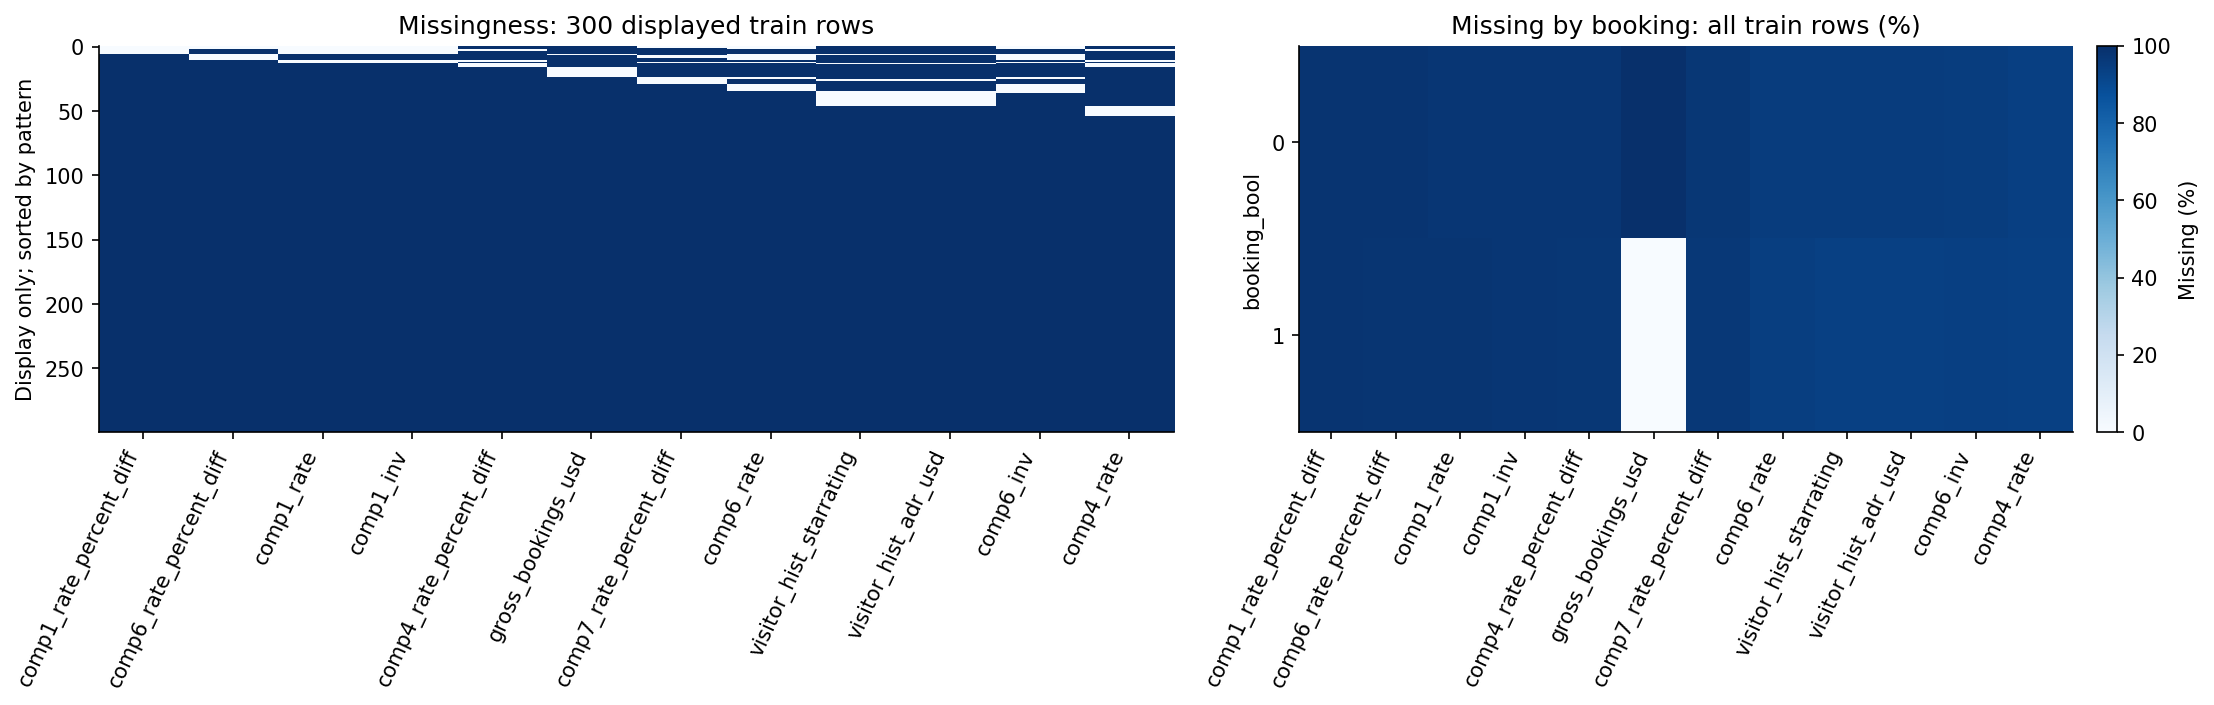

**Quan sát:** comp1_rate_percent_diff thiếu 98.14% trên toàn bộ train; chênh lệch missing lớn nhất giữa hai nhãn là 99.9996 điểm phần trăm ở gross_bookings_usd. Bảng tỷ lệ, số đếm và tương quan cờ thiếu dùng đủ 9,917,530 dòng. Chỉ hình pattern bên trái hiển thị 300 dòng, seed=42, sắp theo pattern, không theo thời gian. Ô xanh là NA. Không suy cơ chế MCAR/MAR/MNAR từ hình; cờ thiếu gross booking vẫn tiết lộ kết quả.

**Phạm vi và cách đọc:** Bảng tổng hợp dùng toàn bộ dữ liệu; hình pattern tối đa 300 dòng seed=42. Không xác định cơ chế MCAR/MAR/MNAR.

### Ngoại lai: lượng hóa trên toàn bộ train

Q1/Q3, hàng rào 1,5×IQR, số đếm và tỷ lệ outlier dùng toàn bộ giá trị không thiếu của từng biến. Boxplot tính từ cùng quần thể đầy đủ; không kết luận giá trị sai chỉ vì vượt hàng rào. Giá trị raw không bị thay thế hoặc xóa.

**Hàng rào IQR và outlier — toàn bộ train**

| Cột gốc | Quần thể/cách tính | nonnull_n | q1 | q3 | iqr | lower_fence | upper_fence | flagged_n | flagged_pct_nonnull | iqr_zero |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| price_usd | toàn bộ train | 9,917,530 | 85 | 185 | 100 | -65 | 335 | 586,503 | 5.9138 | 0 |
| srch_booking_window | toàn bộ train | 9,917,530 | 4 | 49 | 45 | -63.5 | 116.5 | 829,119 | 8.3601 | 0 |
| srch_length_of_stay | toàn bộ train | 9,917,530 | 1 | 3 | 2 | -2 | 6 | 465,314 | 4.6918 | 0 |

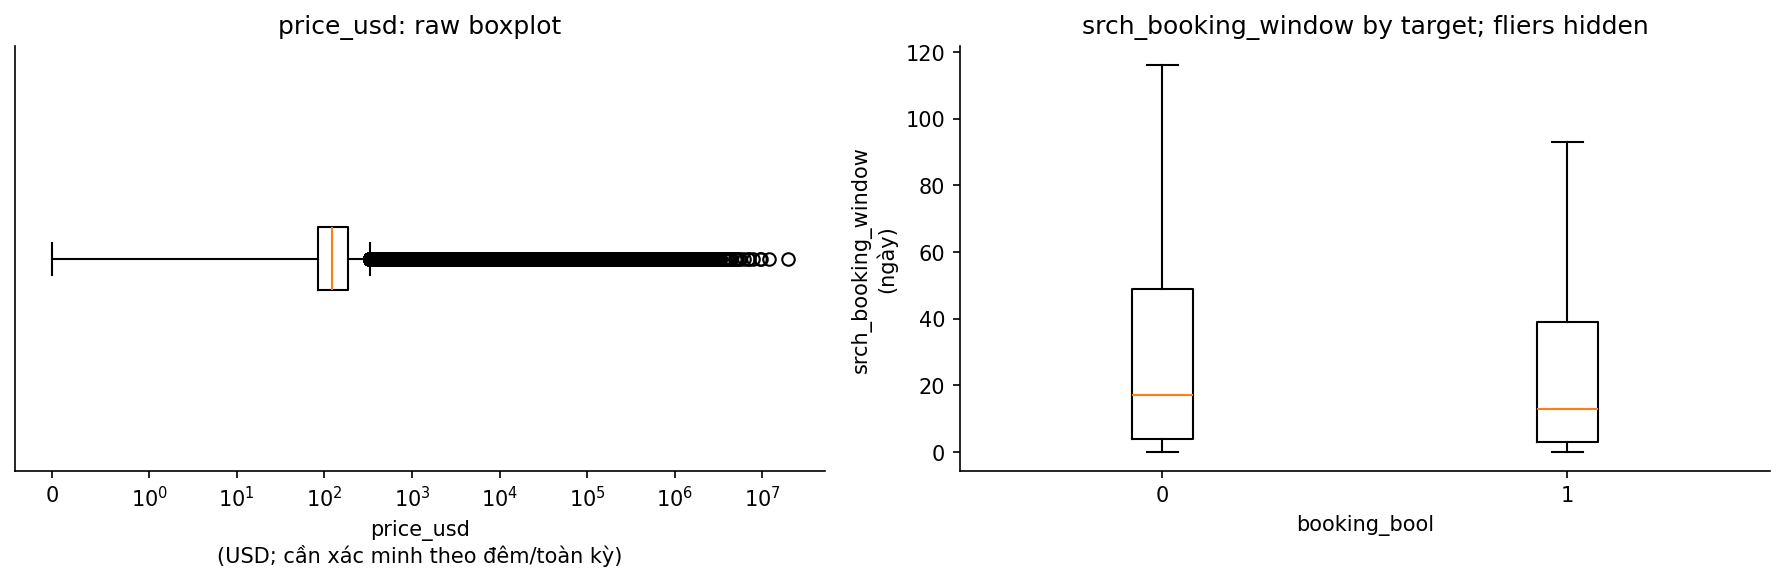

**Quan sát:** theo hàng rào Q1−1,5×IQR và Q3+1,5×IQR, price_usd có 586,503/9,917,530 giá trị bị gắn cờ (5.91%) trong toàn bộ train; đây là bất thường thống kê, chưa phải lỗi nhập liệu. Median srch_booking_window theo nhãn: 0=17.00, 1=13.00. Boxplot bên phải ẩn các điểm ngoài whisker để đọc vùng giữa, không xóa chúng khỏi bảng hay raw. Đơn vị xem từ điển; IQR=0 ở biến rời rạc có thể gắn cờ nhiều giá trị thật. Trục x boxplot raw dùng symlog; hàng rào IQR vẫn tính trên giá trị raw, không phải log.

**Phạm vi và cách đọc:** Quần thể, mẫu số và cửa sổ hiển thị ghi trên hình và bảng cạnh hình. Giữ nguyên giá trị raw; nhóm nhỏ cần đọc thận trọng.

### Vai trò dữ liệu trong thiết kế chính

Bảng quyết định chi tiết từng cột nằm trong phụ lục. Đầu vào của mọi mô hình phải qua kiểm tra t0 trước khi so sánh chất lượng.

**Kiểm kê vai trò**

| Quyết định | Số cột |
| --- | --- |
| Khóa nhóm | 1 |
| Ứng viên có điều kiện | 47 |
| Nhánh mở rộng riêng | 1 |
| Chặn đầu vào chính | 2 |
| Phân tầng thiết kế | 1 |
| Nhãn | 2 |

In [6]:
eda.show_section(report, 'quality_main')

## 4. Phân tích đơn biến

### Phân phối định lượng và phân loại

Mọi cột full_* trong bảng train dùng toàn bộ giá trị không thiếu, gồm cả percentile và skewness. Mean/std nhạy với giá cực lớn; đọc cùng median/p95/p99 và max của cùng quần thể. Bảng có 24 biến định lượng, gồm 8 tỷ lệ chênh giá đối thủ và gross_bookings_usd (cột kết quả, không phải feature). Test chỉ đối chiếu thống kê cơ bản, không tính percentile mẫu. Tỷ trọng category tính theo cặp search-property, không phải khách hoặc search; search nhiều khách sạn đóng góp nhiều dòng hơn.

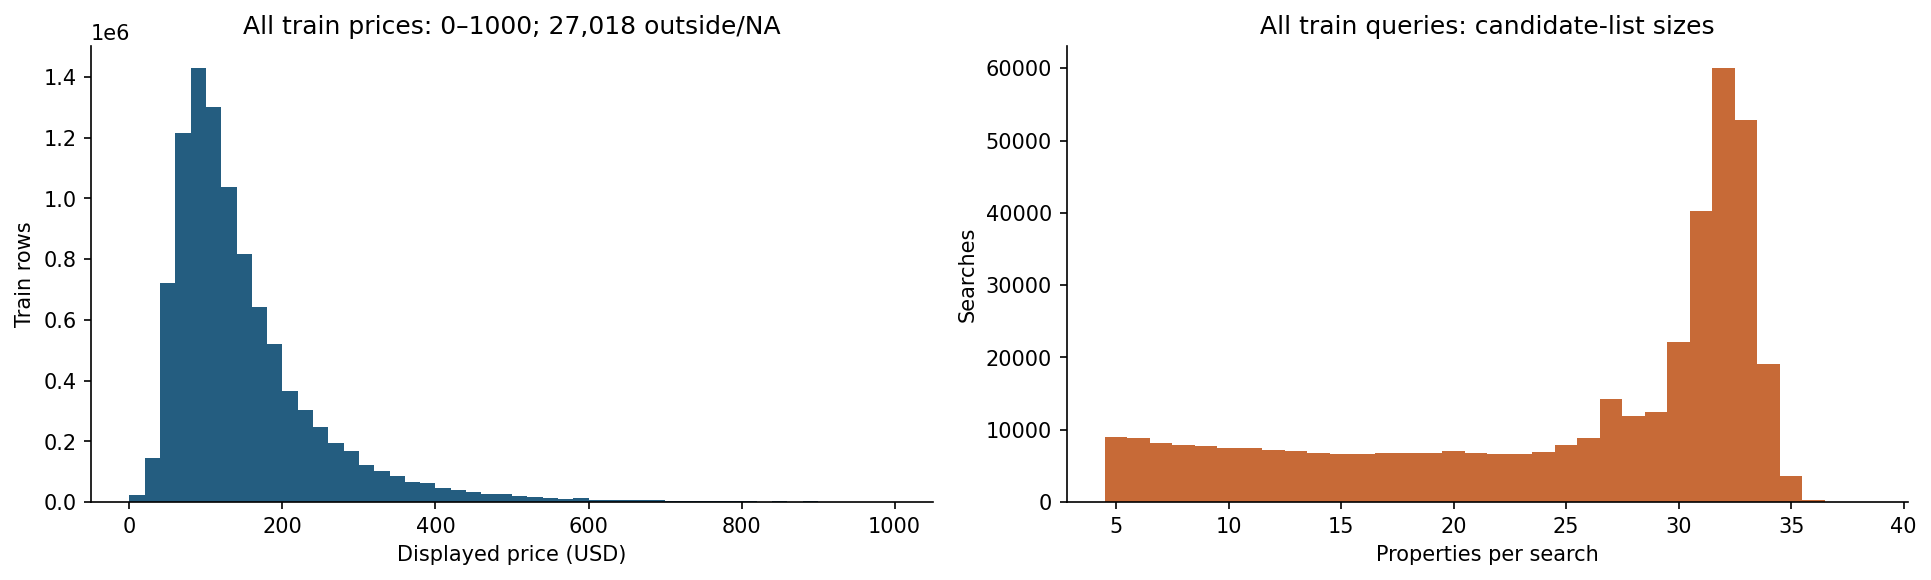

**Quan sát:** trên toàn bộ train, giá có mean 241.78 USD, median 122.07 USD và max 19726328.00 USD, cho thấy đuôi phải lớn. Histogram đếm tất cả giá trong 0–1.000 USD; 27,018 dòng trên 1.000 USD vẫn nằm trong thống kê/boxplot. Phân phối số ứng viên dùng đủ 399,344 searches.

**Phạm vi và cách đọc:** Quần thể, mẫu số và cửa sổ hiển thị ghi trên hình và bảng cạnh hình. Giữ nguyên giá trị raw; nhóm nhỏ cần đọc thận trọng.

### Biến phân loại và nhãn trên toàn bộ train

Hai biểu đồ giữ riêng số cặp và tỷ lệ booking trong mỗi nhóm hạng sao, dùng toàn bộ train.

**Hạng sao — toàn bộ train**

| prop_starrating | Số cặp | Số click | Số booking | Tỷ lệ click (%) | Tỷ lệ booking (%) |
| --- | --- | --- | --- | --- | --- |
| 0 | 337,794 | 9,792 | 5,582 | 2.8988 | 1.6525 |
| 1 | 34,514 | 965 | 439 | 2.796 | 1.2719 |
| 2 | 1,788,994 | 60,596 | 38,892 | 3.3872 | 2.174 |
| 3 | 3,897,419 | 170,869 | 109,049 | 4.3842 | 2.798 |
| 4 | 3,045,848 | 164,118 | 101,691 | 5.3883 | 3.3387 |
| 5 | 812,961 | 37,332 | 20,940 | 4.5921 | 2.5758 |

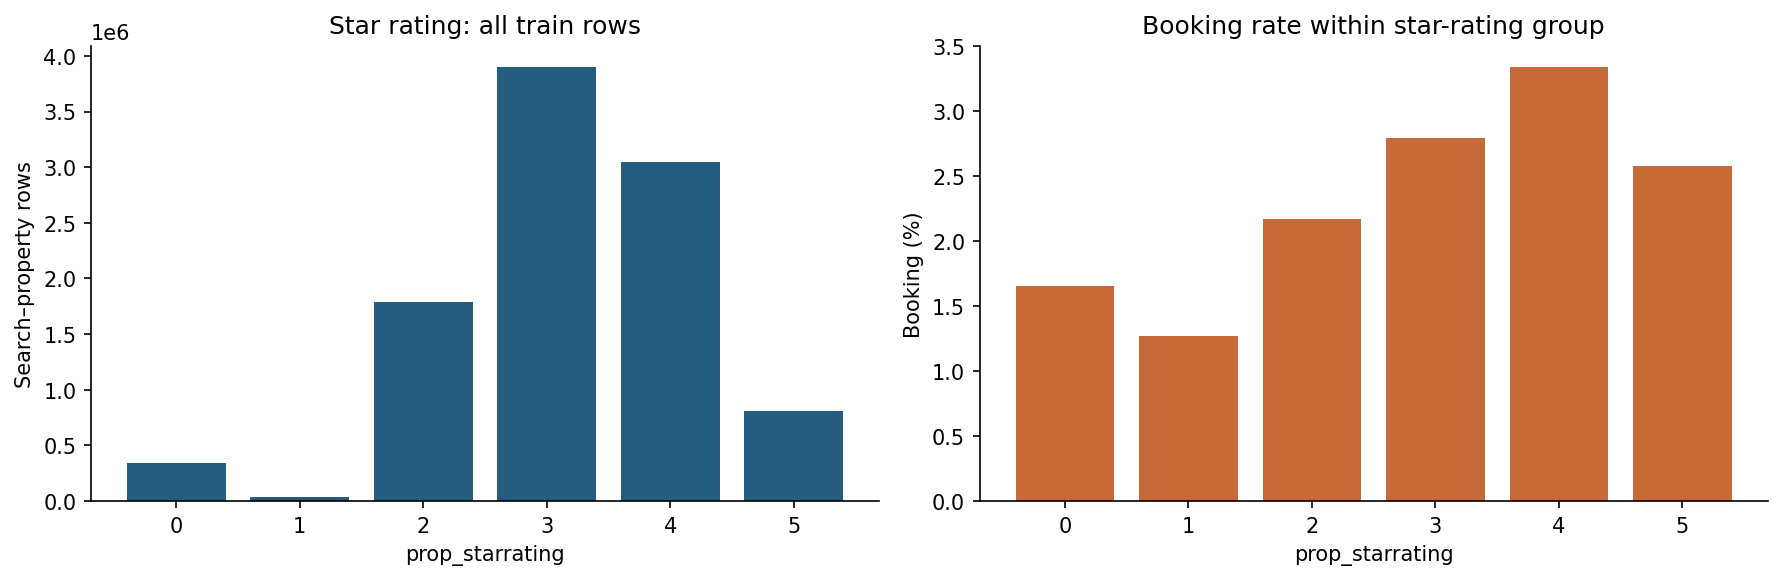

**Quan sát:** trong toàn bộ train, nhóm prop_starrating=4 có booking rate cao nhất trong bảng (3.34%, n=3,045,848); các nhóm có quy mô khác nhau. Mã 0 cần xác minh nghĩa, không mặc định là chất lượng bằng 0; chênh lệch không được điều chỉnh theo giá/vị trí.

**Phạm vi và cách đọc:** Quần thể, mẫu số và cửa sổ hiển thị ghi trên hình và bảng cạnh hình. Giữ nguyên giá trị raw; nhóm nhỏ cần đọc thận trọng.

In [7]:
eda.show_section(report, 'univariate')

## 5. Nhãn, liên hệ đa biến, thời gian và nhóm con

### Mẫu số lượt tìm kiếm, độ dài danh sách và cơ chế sắp xếp

Có 0 search chứa nhiều giá trị random_bool. Bảng so sánh trọng số phân biệt tỷ lệ ở cấp cặp và trung bình tỷ lệ trong từng search: danh sách dài đóng góp nhiều hơn trong tỷ lệ cấp dòng. Booking trung bình theo search là 3.6264%, không phải tỷ lệ search có ít nhất một booking. Không dùng Wilson trên từng cặp vì các ứng viên cạnh tranh trong một search.

**Ảnh hưởng của cách đặt trọng số**

| Quần thể/cách tính | Số đơn vị | Tỷ lệ click (%) | Tỷ lệ booking (%) |
| --- | --- | --- | --- |
| Mỗi cặp có trọng số bằng nhau | 9,917,530 | 4.4736 | 2.7889 |
| Mỗi search có trọng số bằng nhau | 399,344 | 5.817 | 3.6264 |

### Độ mạnh liên hệ với click và booking

Tính V từ bảng chéo đếm đủ train; không lấy mẫu cho thống kê. Giá và thời gian đặt trước dùng các khoảng EDA đã công bố. Số nhóm và cách chia khoảng ảnh hưởng V. Không so hệ số này với tương quan của các biến số hoặc xếp hạng tự động đầu vào.

**Mười góc nhìn phân nhóm với hai nhãn**

| Biến | Thước đo | Số nhóm | Số cặp | V với click | V với booking |
| --- | --- | --- | --- | --- | --- |
| site_id | Cramér V | 34 | 9,917,530 | 0.0117 | 0.0115 |
| visitor_location_country_id | Cramér V | 218 | 9,917,530 | 0.0123 | 0.008 |
| prop_country_id | Cramér V | 172 | 9,917,530 | 0.0179 | 0.0154 |
| prop_starrating | Cramér V | 6 | 9,917,530 | 0.0365 | 0.0283 |
| prop_brand_bool | Cramér V | 2 | 9,917,530 | 0.0013 | 0.0105 |
| promotion_flag | Cramér V | 2 | 9,917,530 | 0.0398 | 0.0361 |
| srch_saturday_night_bool | Cramér V | 2 | 9,917,530 | 0.0011 | 0.0055 |
| random_bool | Cramér V | 2 | 9,917,530 | 0.0058 | 0.0887 |
| price_group | Cramér V | 8 | 9,917,530 | 0.0251 | 0.0331 |
| window_group | Cramér V | 7 | 9,917,530 | 0.0026 | 0.0225 |

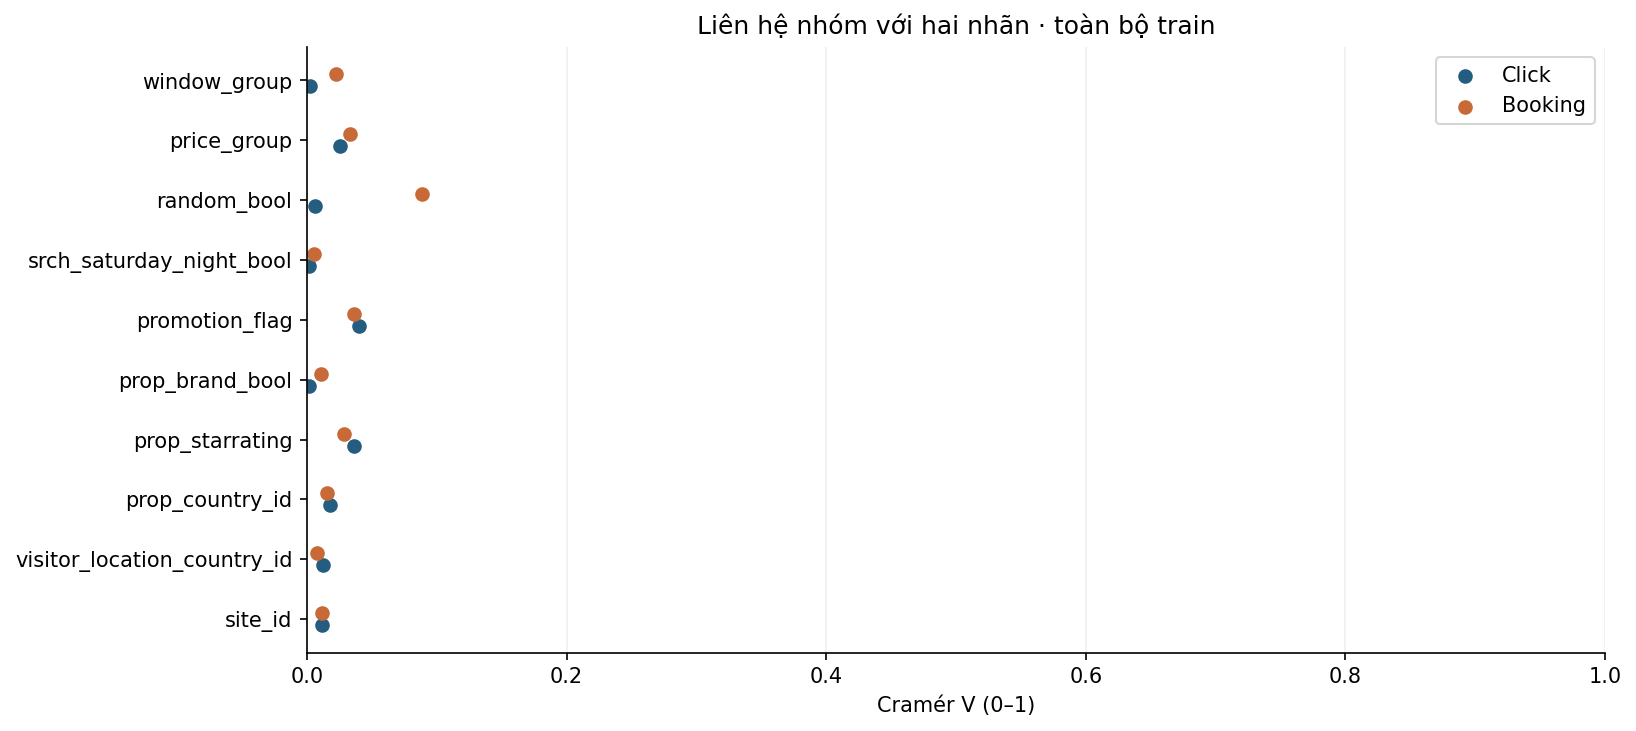

**Quan sát:** mỗi biến có hai điểm cho liên hệ với click và booking, cho phép kiểm tra liệu tín hiệu hai hành vi có đồng nhất.

**Phạm vi và cách đọc:** toàn bộ train; chỉ mười cách nhóm công bố, chưa phải toàn bộ 49 cột ứng viên. Cramér V không hiệu chỉnh số nhóm, không là điểm chất lượng mô hình hoặc quan hệ nhân quả. Không dùng p-value giả định 9.9 triệu dòng độc lập.

### Mối liên hệ với click/booking theo nhóm

Tất cả bảng dùng toàn bộ train. Phân nhóm giá và booking window chỉ là công cụ đọc bảng EDA; không xuất feature. Tỷ lệ có thể phản ánh vị trí hiển thị, thành phần search, thương hiệu, thời gian và cơ chế chọn mẫu cùng lúc. Không coi chênh lệch promotion_flag là uplift từ khuyến mãi. Bảng không kiểm định nhiều giả thuyết hoặc khẳng định quan hệ nhân quả.

**Tỷ lệ click/booking theo prop_starrating; mẫu số là số cặp trong nhóm**

| prop_starrating | Số cặp | Số click | Số booking | Tỷ lệ click (%) | Tỷ lệ booking (%) | Nhóm dưới 100 |
| --- | --- | --- | --- | --- | --- | --- |
| 0 | 337,794 | 9,792 | 5,582 | 2.8988 | 1.6525 | 0 |
| 1 | 34,514 | 965 | 439 | 2.796 | 1.2719 | 0 |
| 2 | 1,788,994 | 60,596 | 38,892 | 3.3872 | 2.174 | 0 |
| 3 | 3,897,419 | 170,869 | 109,049 | 4.3842 | 2.798 | 0 |
| 4 | 3,045,848 | 164,118 | 101,691 | 5.3883 | 3.3387 | 0 |
| 5 | 812,961 | 37,332 | 20,940 | 4.5921 | 2.5758 | 0 |

**Tỷ lệ click/booking theo price_group; mẫu số là số cặp trong nhóm**

... (3 outputs left out)

### Tương quan và tương tác — toàn bộ train

Ma trận Spearman của 9 biến dùng toàn bộ cặp không thiếu, xếp hạng lại riêng từng cặp. Số cặp hợp lệ có tại phụ lục. Chỉ scatter hiển thị tối đa 4.000 điểm seed=42. Chưa thực hiện kiểm định nhiều giả thuyết hoặc kết luận nhân quả/đa cộng tuyến từ tương quan.

**Ma trận Spearman — toàn bộ train**

| Cột gốc | price_usd | prop_starrating | prop_review_score | prop_location_score1 | prop_location_score2 | prop_log_historical_price | srch_length_of_stay | srch_booking_window | srch_room_count |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| price_usd | 1 | 0.5523 | 0.4197 | 0.309 | 0.1616 | 0.5698 | 0.1447 | 0.1818 | 0.0166 |
| prop_starrating | 0.5523 | 1 | 0.4247 | 0.323 | 0.1371 | 0.5011 | 0.1243 | 0.1142 | 0.0372 |
| prop_review_score | 0.4197 | 0.4247 | 1 | 0.1141 | 0.0631 | 0.3443 | 0.0197 | 0.0361 | 0.0106 |
| prop_location_score1 | 0.309 | 0.323 | 0.1141 | 1 | 0.5334 | 0.315 | 0.1724 | 0.1524 | 0.0275 |
| prop_location_score2 | 0.1616 | 0.1371 | 0.0631 | 0.5334 | 1 | 0.1554 | 0.0196 | 0.0418 | -0.0331 |
| prop_log_historical_price | 0.5698 | 0.5011 | 0.3443 | 0.315 | 0.1554 | 1 | 0.1287 | 0.137 | 0.0105 |
| srch_length_of_stay | 0.1447 | 0.1243 | 0.0197 | 0.1724 | 0.0196 | 0.1287 | 1 | 0.3391 | 0.0153 |
| srch_booking_window | 0.1818 | 0.1142 | 0.0361 | 0.1524 | 0.0418 | 0.137 | 0.3391 | 1 | 0.0564 |
| srch_room_count | 0.0166 | 0.0372 | 0.0106 | 0.0275 | -0.0331 | 0.0105 | 0.0153 | 0.0564 | 1 |

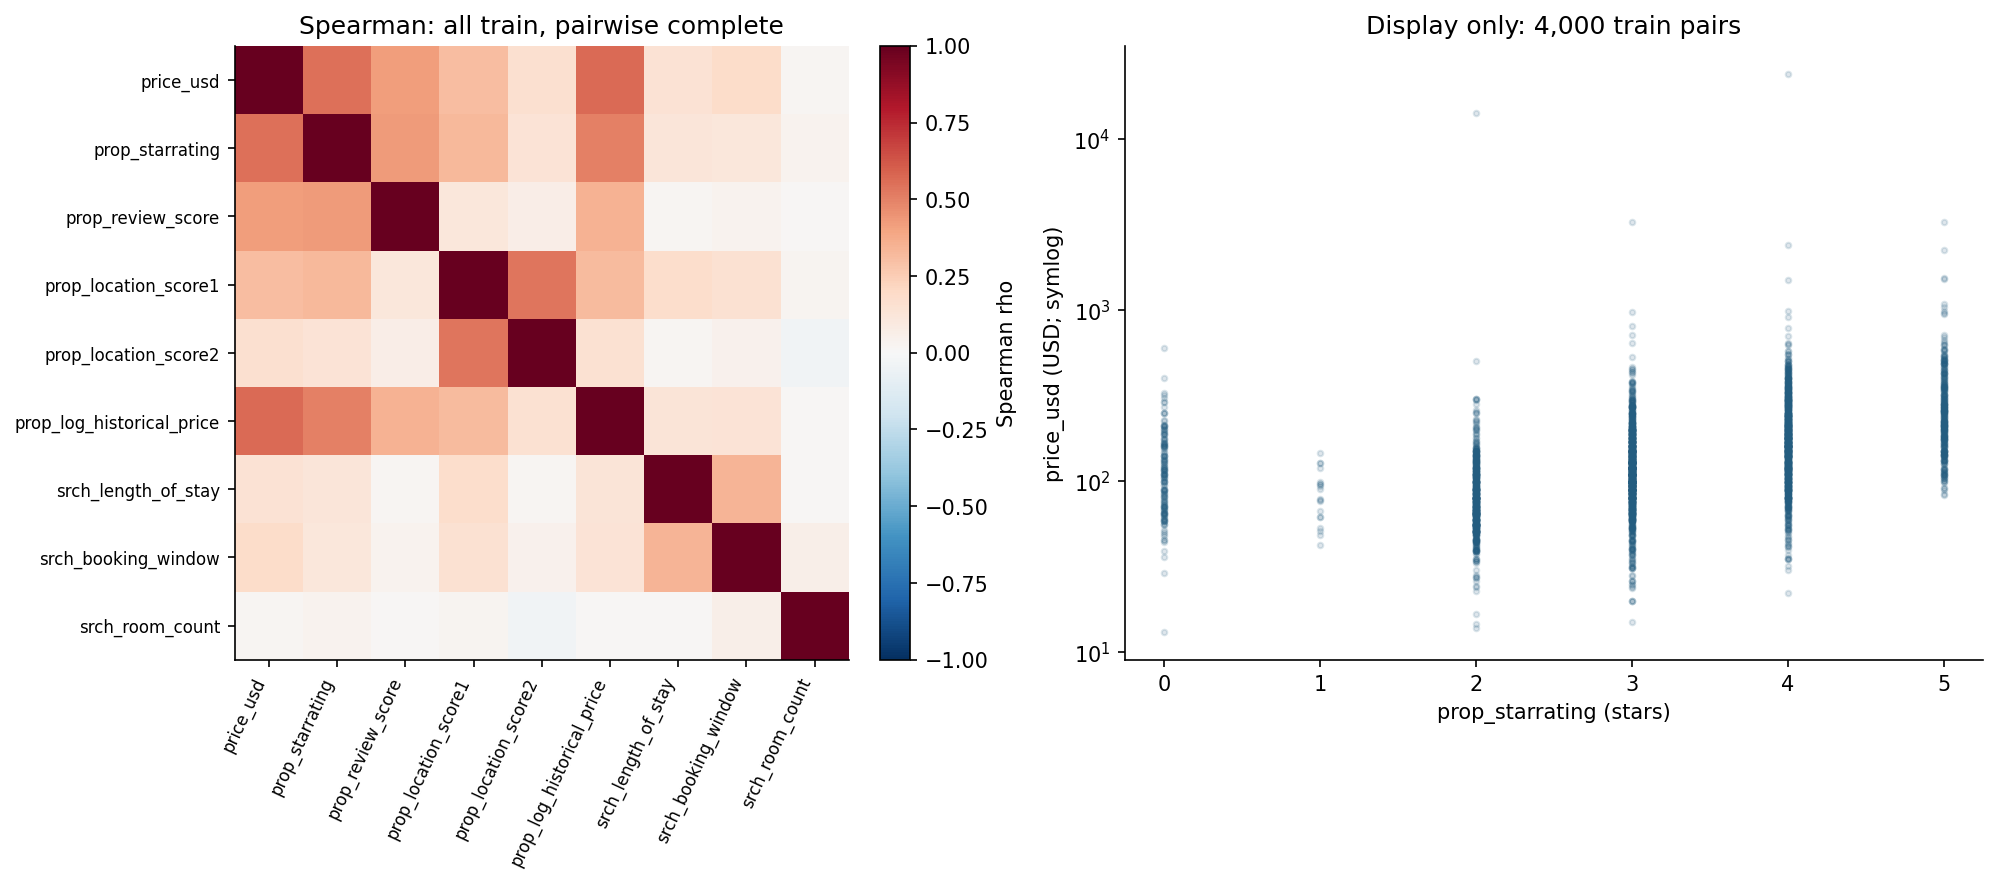

**Quan sát:** Spearman giá–hạng sao trên toàn bộ cặp hợp lệ của train là 0.552; cặp có |rho| lớn nhất trong ma trận là price_usd–prop_log_historical_price (rho=0.570, n=9,917,530). Ma trận tính lại thứ hạng trên các dòng không thiếu của từng cặp; số dòng từng cặp ở phụ lục. Scatter chỉ hiển thị tối đa 4.000 điểm, seed=42, trục y symlog để đọc đuôi dài. Không biến đổi raw, không chọn feature hoặc kết luận nhân quả/đa cộng tuyến từ tương quan.

**Phạm vi và cách đọc:** Tương quan dùng từng cặp không thiếu; scatter tối đa 4.000 điểm chỉ để hiển thị.

### Vị trí hiển thị và cơ chế tiếp xúc

`position` và `random_bool` cần được đọc cùng nhau: khách sạn được hiển thị ở vị trí khác nhau có cơ hội được xem/click khác nhau. Biểu đồ mô tả liên hệ trong từng giá trị cờ; không ước lượng tác động nhân quả của vị trí, xác suất exposure hoặc áp dụng hiệu chỉnh bias. Theo [nghiên cứu dùng dữ liệu Expedia](https://hamsabastani.github.io/proxies.pdf), random_bool=1 đánh dấu danh sách được sắp ngẫu nhiên; vẫn cần xác minh định nghĩa và quy trình tạo tập trước khi suy luận can thiệp. Không dùng position làm feature mặc định cho schema test hiện có.

**Toàn bộ random_bool × position, giữ số dòng mỗi ô**

| random_bool | position | Số cặp | Số click | Số booking | Tỷ lệ click (%) | Tỷ lệ booking (%) |
| --- | --- | --- | --- | --- | --- | --- |
| 0 | 1 | 277,662 | 59,827 | 54,126 | 21.5467 | 19.4935 |
| 0 | 2 | 277,652 | 40,678 | 35,974 | 14.6507 | 12.9565 |
| 0 | 3 | 277,622 | 31,088 | 27,062 | 11.198 | 9.7478 |
| 0 | 4 | 266,073 | 24,500 | 21,057 | 9.208 | 7.914 |
| 0 | 5 | 16,672 | 321 | 199 | 1.9254 | 1.1936 |
| 0 | 6 | 277,308 | 19,837 | 16,885 | 7.1534 | 6.0889 |
| 0 | 7 | 271,435 | 16,238 | 13,657 | 5.9823 | 5.0314 |
| 0 | 8 | 265,486 | 13,722 | 11,479 | 5.1686 | 4.3238 |
| 0 | 9 | 259,865 | 11,499 | 9,527 | 4.425 | 3.6661 |
| 0 | 10 | 237,876 | 10,018 | 8,266 | 4.2114 | 3.4749 |
| 0 | 11 | 20,337 | 153 | 68 | 0.7523 | 0.3344 |
| 0 | 12 | 249,246 | 8,683 | 7,134 | 3.4837 | 2.8622 |
| 0 | 13 | 244,658 | 7,641 | 6,169 | 3.1231 | 2.5215 |
| 0 | 14 | 239,642 | 6,720 | 5,442 | 2.8042 | 2.2709 |
| 0 | 15 | 234,762 | 6,203 | 4,985 | 2.6423 | 2.1234 |
| 0 | 16 | 212,417 | 5,301 | 4,275 | 2.4956 | 2.0126 |
| 0 | 17 | 20,557 | 85 | 32 | 0.4135 | 0.1557 |
| 0 | 18 | 225,419 | 4,873 | 3,869 | 2.1618 | 1.7164 |
| 0 | 19 | 220,940 | 4,366 | 3,477 | 1.9761 | 1.5737 |
| 0 | 20 | 216,469 | 3,973 | 3,147 | 1.8354 | 1.4538 |
| 0 | 21 | 211,938 | 3,674 | 2,861 | 1.7335 | 1.3499 |
| 0 | 22 | 190,234 | 3,162 | 2,437 | 1.6622 | 1.2811 |
| 0 | 23 | 19,674 | 59 | 22 | 0.2999 | 0.1118 |
| 0 | 24 | 202,691 | 3,051 | 2,357 | 1.5052 | 1.1629 |
| 0 | 25 | 198,022 | 2,676 | 2,114 | 1.3514 | 1.0676 |
| 0 | 26 | 193,411 | 2,490 | 1,957 | 1.2874 | 1.0118 |
| 0 | 27 | 188,936 | 2,375 | 1,825 | 1.257 | 0.9659 |
| 0 | 28 | 184,559 | 2,090 | 1,619 | 1.1324 | 0.8772 |
| 0 | 29 | 179,912 | 1,865 | 1,430 | 1.0366 | 0.7948 |
| 0 | 30 | 174,730 | 1,737 | 1,321 | 0.9941 | 0.756 |
| 0 | 31 | 168,703 | 1,606 | 1,225 | 0.952 | 0.7261 |
| 0 | 32 | 159,192 | 1,427 | 1,071 | 0.8964 | 0.6728 |
| 0 | 33 | 150,677 | 1,294 | 1,005 | 0.8588 | 0.667 |
| 0 | 34 | 142,218 | 1,217 | 930 | 0.8557 | 0.6539 |
| 0 | 35 | 127,223 | 1,003 | 744 | 0.7884 | 0.5848 |
| 0 | 36 | 99,323 | 727 | 576 | 0.732 | 0.5799 |
| 0 | 37 | 55,520 | 401 | 315 | 0.7223 | 0.5674 |
| 0 | 38 | 16,424 | 119 | 96 | 0.7245 | 0.5845 |
| 0 | 39 | 2,293 | 16 | 12 | 0.6978 | 0.5233 |
| 0 | 40 | 100 | 1 | 1 | 1 | 1 |
| 1 | 1 | 120,907 | 17,171 | 2,227 | 14.2018 | 1.8419 |
| 1 | 2 | 120,814 | 13,056 | 1,749 | 10.8067 | 1.4477 |
| 1 | 3 | 120,862 | 10,962 | 1,505 | 9.0698 | 1.2452 |
| 1 | 4 | 120,354 | 9,414 | 1,202 | 7.8219 | 0.9987 |
| 1 | 5 | 1,928 | 108 | 14 | 5.6017 | 0.7261 |
| 1 | 6 | 120,792 | 8,446 | 1,036 | 6.9922 | 0.8577 |
| 1 | 7 | 117,788 | 7,223 | 885 | 6.1322 | 0.7513 |
| 1 | 8 | 114,876 | 6,298 | 718 | 5.4824 | 0.625 |
| 1 | 9 | 112,146 | 5,784 | 641 | 5.1576 | 0.5716 |
| 1 | 10 | 108,891 | 5,105 | 605 | 4.6882 | 0.5556 |
| 1 | 11 | 1,990 | 42 | 4 | 2.1106 | 0.201 |
| 1 | 12 | 107,088 | 4,621 | 544 | 4.3151 | 0.508 |
| 1 | 13 | 104,762 | 4,265 | 474 | 4.0711 | 0.4525 |
| 1 | 14 | 102,376 | 3,864 | 432 | 3.7743 | 0.422 |
| 1 | 15 | 100,146 | 3,596 | 386 | 3.5908 | 0.3854 |
| 1 | 16 | 96,956 | 3,418 | 328 | 3.5253 | 0.3383 |
| 1 | 17 | 1,941 | 13 | 0 | 0.6698 | 0 |
| 1 | 18 | 95,593 | 3,037 | 318 | 3.177 | 0.3327 |
| 1 | 19 | 93,463 | 2,854 | 278 | 3.0536 | 0.2974 |
| 1 | 20 | 91,379 | 2,806 | 261 | 3.0707 | 0.2856 |
| 1 | 21 | 89,204 | 2,505 | 231 | 2.8082 | 0.259 |
| 1 | 22 | 86,184 | 2,365 | 206 | 2.7441 | 0.239 |
| 1 | 23 | 1,781 | 19 | 2 | 1.0668 | 0.1123 |
| 1 | 24 | 84,954 | 2,197 | 219 | 2.5861 | 0.2578 |
| 1 | 25 | 82,742 | 1,999 | 179 | 2.4159 | 0.2163 |
| 1 | 26 | 80,651 | 1,992 | 200 | 2.4699 | 0.248 |
| 1 | 27 | 78,535 | 1,815 | 163 | 2.3111 | 0.2076 |
| 1 | 28 | 76,412 | 1,718 | 161 | 2.2483 | 0.2107 |
| 1 | 29 | 74,179 | 1,606 | 123 | 2.165 | 0.1658 |
| 1 | 30 | 71,690 | 1,544 | 114 | 2.1537 | 0.159 |
| 1 | 31 | 69,025 | 1,478 | 148 | 2.1413 | 0.2144 |
| 1 | 32 | 64,381 | 1,298 | 115 | 2.0161 | 0.1786 |
| 1 | 33 | 60,834 | 1,269 | 113 | 2.086 | 0.1858 |
| 1 | 34 | 56,515 | 1,117 | 94 | 1.9765 | 0.1663 |
| 1 | 35 | 48,503 | 939 | 80 | 1.936 | 0.1649 |
| 1 | 36 | 34,954 | 619 | 50 | 1.7709 | 0.143 |
| 1 | 37 | 18,293 | 316 | 29 | 1.7274 | 0.1585 |
| 1 | 38 | 4,952 | 65 | 9 | 1.3126 | 0.1817 |
| 1 | 39 | 781 | 12 | 2 | 1.5365 | 0.2561 |
| 1 | 40 | 30 | 0 | 0 | 0 | 0 |

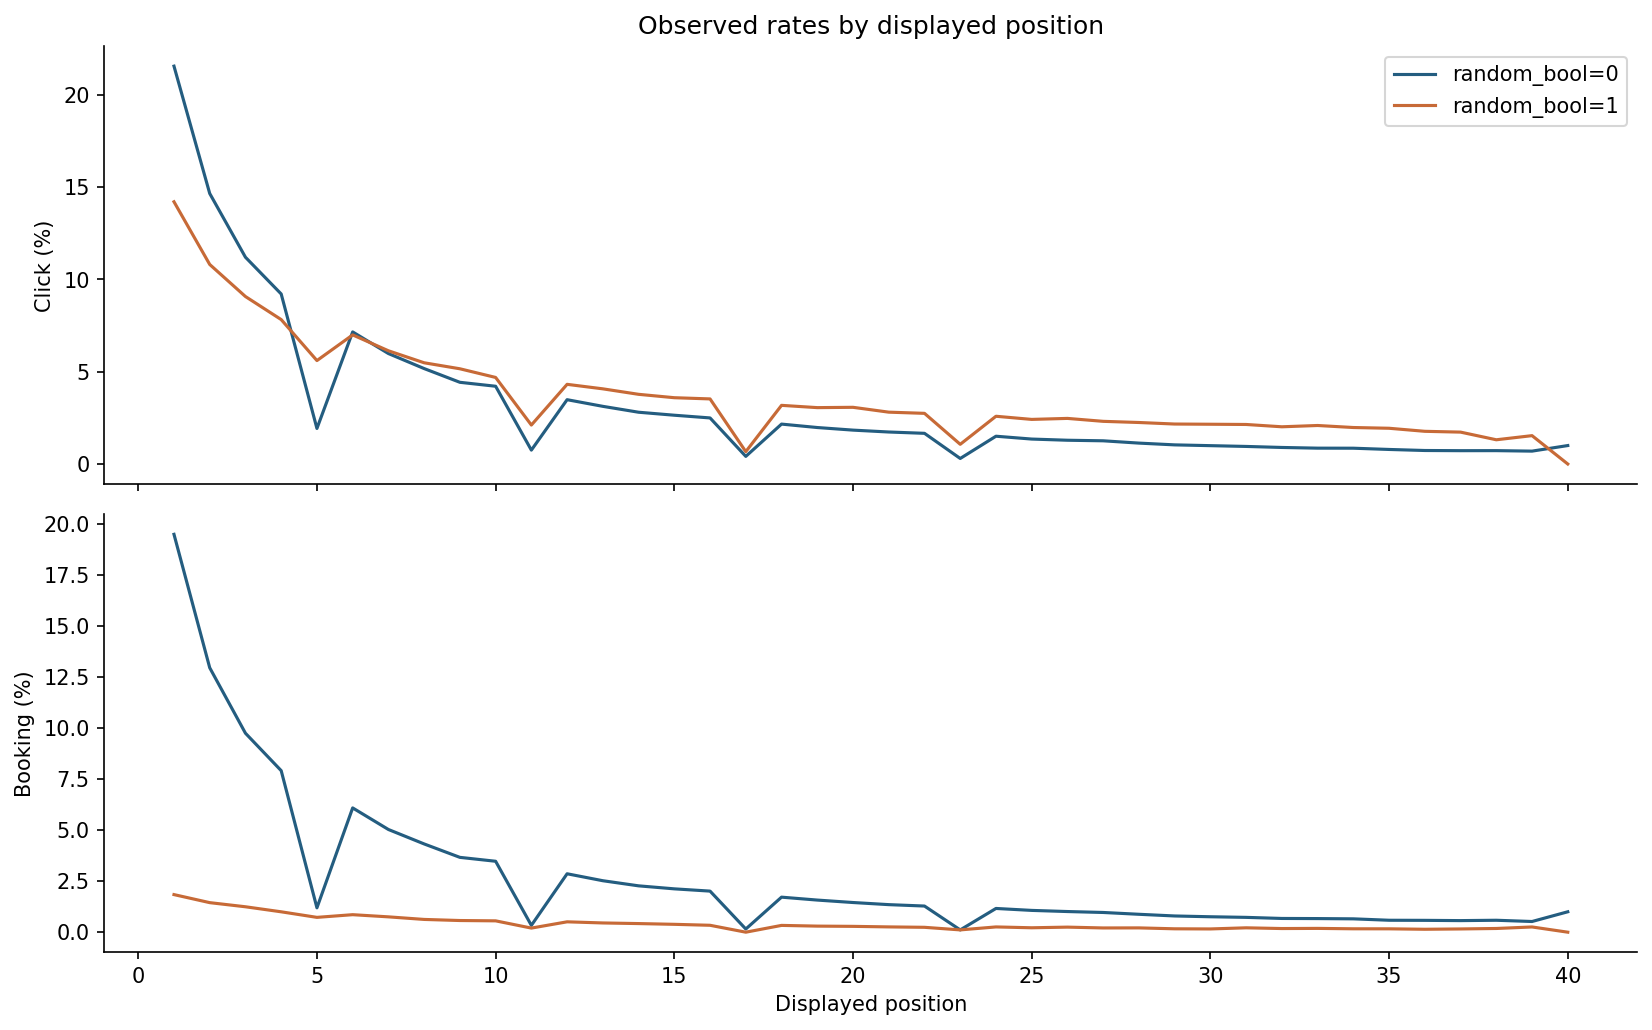

**Quan sát:** tại vị trí nhỏ nhất quan sát được, random_bool=0: click 21.55%, booking 19.49%, n=277,662; random_bool=1: click 14.20%, booking 1.84%, n=120,907. Chênh lệch giữa các cơ chế xếp hạng và sự phụ thuộc theo vị trí cho thấy CTR không chỉ phản ánh sở thích; đây chưa phải ước lượng nhân quả của thứ hạng.

**Phạm vi và cách đọc:** Toàn bộ train, phân tầng random_bool. Vị trí là cơ chế tiếp xúc; không diễn giải thành tác động nhân quả.

### Thời gian và so sánh train–test

Khoảng thời gian và phân bố category được tính trực tiếp, không giả định test nằm sau train. Tháng đầu/cuối có thể không đầy đủ. Total variation so sánh phân phối category ở cấp dòng, không đại diện đầy đủ cho drift ở cấp search/user. Test không có nhãn nên không tính click/booking rate cho test. Bất kỳ đánh giá tương lai nào ở giai đoạn sau cần giữ nguyên srch_id trong một tập và thiết kế thời gian theo mục tiêu triển khai; chưa thực hiện chia tập ở đây.

**Khoảng thời gian toàn bộ mỗi tập**

| Quần thể/cách tính | min_date_time | max_date_time | Số lượt tìm kiếm |
| --- | --- | --- | --- |
| train | 2012-11-01 00:01:37 | 2013-06-30 23:58:24 | 399,344 |
| test | 2012-11-01 00:03:24 | 2013-06-30 23:57:15 | 266,230 |

**Khác biệt category train–test, toàn bộ dòng**

| Cột gốc | Khác biệt phân phối (0–1) | Nhóm chỉ có ở test |
| --- | --- | --- |
| srch_destination_id | 0.0961 | 4,701 |
| prop_country_id | 0.0053 | 2 |
| visitor_location_country_id | 0.0048 | 5 |
| site_id | 0.0025 | 0 |
| comp3_inv | 0.0016 | 0 |
| comp3_rate | 0.0016 | 0 |
| srch_saturday_night_bool | 0.0014 | 0 |
| comp5_inv | 0.0013 | 0 |
| comp5_rate | 0.0012 | 0 |
| random_bool | 0.001 | 0 |
| comp8_rate | 0.0009 | 0 |
| comp7_inv | 0.0008 | 0 |
| prop_starrating | 0.0008 | 0 |
| comp8_inv | 0.0008 | 0 |
| comp7_rate | 0.0008 | 0 |
| comp4_inv | 0.0006 | 0 |
| comp4_rate | 0.0006 | 0 |
| comp6_inv | 0.0005 | 0 |
| comp1_rate | 0.0004 | 0 |
| comp1_inv | 0.0004 | 0 |
| comp6_rate | 0.0004 | 0 |
| comp2_rate | 0.0004 | 0 |
| comp2_inv | 0.0003 | 0 |
| prop_brand_bool | 0.0002 | 0 |
| promotion_flag | 0.0002 | 0 |

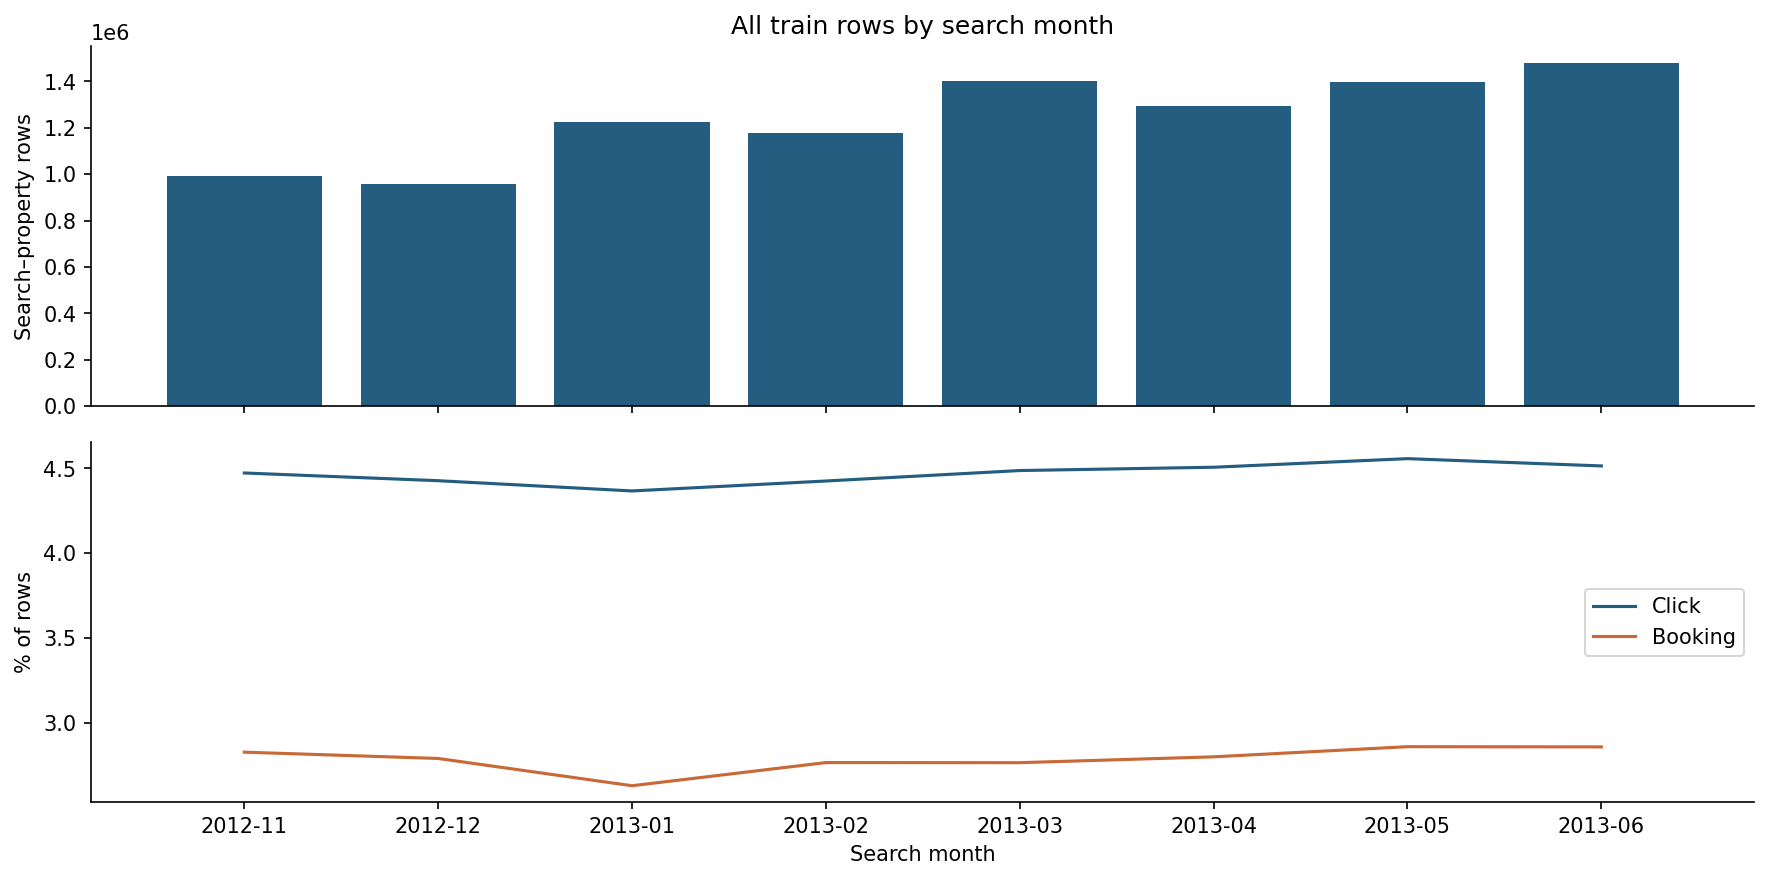

**Quan sát:** tỷ lệ click theo tháng dao động 4.37–4.56%, booking 2.63–2.86% trong train. Khoảng thời gian chưa đủ nhiều chu kỳ năm để khẳng định mùa vụ bền vững; quy mô dòng còn phụ thuộc số property/search.

**Phạm vi và cách đọc:** Số lượng và tỷ lệ theo năm–tháng; tháng đầu/cuối có thể thiếu ngày. Không kết luận mùa vụ chỉ từ số tháng gộp.

In [8]:
eda.show_section(report, 'multivariate_main')

## 6. Tổng hợp giới hạn và mức độ phù hợp

In [9]:
eda.show_section(report, 'risks')

Tách điều đã quan sát khỏi nguyên nhân chưa được chứng minh. Không diễn giải chênh lệch nhóm thành đặc điểm cố hữu của giới tính/tuổi/quốc gia và không thực hiện nhận diện lại cá nhân.

**Rủi ro và giới hạn sử dụng**

| Vấn đề | Bằng chứng hoặc giới hạn |
| --- | --- |
| Quyền riêng tư | Không có user ID trực tiếp trong schema; thời gian, vị trí quốc gia và hồ sơ lịch sử vẫn là thông tin hành vi. Không suy lại danh tính. |
| Quần thể | Train không có search không click; xếp hạng, exposure và cách chọn mẫu làm tỷ lệ khác toàn bộ traffic. |
| Phụ thuộc / bias | Nhiều property trong một search phụ thuộc nhau; chưa có user ID để kiểm soát searches lặp của cùng người. |
| Rò rỉ | gross_bookings_usd là kết quả; position không có trong test; click tương lai không dùng để dự đoán trước click. |
| Đồng ý / quyền sử dụng | CSV không có biểu mẫu đồng ý hay hồ sơ pháp lý thu thập. Không suy dữ liệu công khai = đồng ý cho mọi mục đích; đọc điều khoản nguồn, không tự gán giấy phép mở. |
| Giới hạn suy luận | EDA là mô tả, không phải kiểm định tác động can thiệp. Khoảng Wilson nếu có chỉ theo giả định độc lập; chưa đánh giá chất lượng mô hình hoặc tính công bằng của mô hình. |

### Kết luận và hướng nghiên cứu

### Kết luận và câu hỏi còn mở

**Đã kiểm chứng trên toàn bộ train:** 9,917,530 cặp search-property thuộc 399,344 searches; click 4.47%, booking 2.79%, booking/click 62.34%. Không có search hoàn toàn không click trong tập train hiện tại. Số cột đối thủ là 24 và tỷ lệ missing khác nhau mạnh theo đối thủ. Gross bookings là kết quả; position không có trong test.

**Mức độ phù hợp:** phù hợp nghiên cứu propensity/xếp hạng ở cấp khách sạn trong search, chưa phải propensity marketing theo user hoặc CTR/CVR toàn website. Two-stage click/booking là một khả năng định nghĩa bài toán, không phải kết luận bắt buộc từ tỷ số booking/click cao.

**Cần xác minh:** cơ chế đưa search vào dữ liệu và nhóm không click bị thiếu; tính sẵn có của từng điểm do Expedia sinh; nghĩa/đơn vị và cách hình thành giá; quy trình random_bool; khả năng nhận diện người dùng và lần tìm kiếm lặp; phạm vi áp dụng ngoài dữ liệu lịch sử.

Không class weighting, resampling, imputation, clipping, encoding, feature engineering hay train/rank model. Không tạo tập processed hoặc tự quyết định loại cột missing cao. Các câu hỏi và thống kê ở đây phục vụ hiểu dữ liệu trước giai đoạn tiếp theo.

... (4 outputs left out)

### Câu hỏi mở và cách xác minh

Đã mở [trang dữ liệu Kaggle](https://www.kaggle.com/competitions/expedia-personalized-sort/data) ngày 2026-11-02 nhưng công cụ web không đọc được nội dung; liên kết là nguồn cần xác minh, không phải bằng chứng đã xác nhận. Vai trò trong bảng là đề xuất theo dõi, chưa phải người đã nhận việc. Ngày tải/mã phiên bản chưa được ghi nhận; giữ SHA-256 để định danh bản local.

**Danh mục xác minh**

| Câu hỏi | Thông tin còn thiếu | Nguồn có thể trả lời | Cách xác minh | Điều kiện kết thúc hoặc quyết định | Vai trò đề xuất | Trạng thái |
| --- | --- | --- | --- | --- | --- | --- |
| E-Q1 · Chọn mẫu | Vì sao mọi search train có click, và áp dụng cho quần thể nào? | https://www.kaggle.com/competitions/expedia-personalized-sort/data | Xin quy trình chọn search và dữ liệu search không click | Giới hạn mô hình trong mẫu đã chọn; mở rộng website chỉ khi có quần thể đích | Tác giả tổng hợp; người cung cấp dữ liệu xác nhận; người hướng dẫn duyệt phạm vi | Mở · chưa đủ bằng chứng |
| E-Q2 · Thời điểm nhãn | Click/booking được ghi đến lúc nào sau date_time? | https://www.kaggle.com/competitions/expedia-personalized-sort/data | Xin timestamp sự kiện, quy tắc gán nhãn và hạn theo dõi | Xác nhận nhãn sẵn có trước mốc học; khoảng đệm 7 ngày chưa đủ bằng chứng | Tác giả tổng hợp; người cung cấp dữ liệu xác nhận; người hướng dẫn duyệt phạm vi | Mở · chưa đủ bằng chứng |
| E-Q3 · Tiếp xúc và đầu vào | Cờ random và điểm khách sạn/giá được tạo khi nào? | https://www.kaggle.com/competitions/expedia-personalized-sort/data | Đối chiếu cơ chế phân bổ vị trí, timestamp từng điểm và snapshot giá | Duyệt đầu vào tại t0; chỉ nghiên cứu nhân quả khi có thiết kế tiếp xúc phù hợp | Tác giả tổng hợp; người cung cấp dữ liệu xác nhận; người hướng dẫn duyệt phạm vi | Mở · chưa đủ bằng chứng |

## 7. Thuật toán và thiết kế đánh giá đề xuất

### Baseline, mô hình chính và xác suất

Các nhánh dưới đây là đặc tả đề xuất, chưa tạo feature, fit mô hình hoặc hiệu chỉnh. Mọi ứng viên so sánh trên cùng tập thông tin đã được chấp nhận tại t0.

**Nhánh đầu vào**

| Nhánh | Thông tin | Điều kiện |
| --- | --- | --- |
| E0 · Trước hiển thị | Ngữ cảnh search, thuộc tính khách sạn và giá đã xác nhận tại t0 | Loại srch_id khỏi feature; không dùng position, click, gross và random_bool |
| E1 · Điểm lịch sử/đối thủ | Bổ sung các điểm Expedia, lịch sử và 24 cột đối thủ có bằng chứng tại t0 | Chỉ tính lịch sử từ quá khứ; missing không tự suy ra không có đối thủ |
| E2 · Định danh khách sạn | E0/E1 + prop_id dạng category | So với nhánh không ID và báo riêng khách sạn mới; không target-encode bằng toàn dữ liệu |

**Ứng viên và đối chứng**

| Ứng viên | Vai trò | Kiểm soát |
| --- | --- | --- |
| Xác suất hằng | Tỷ lệ click/booking riêng của train | Hai nhãn riêng; chỉ có nghĩa trong quần thể search đã chọn |
| Logistic Regression L2 | Hiệu ứng chính và giá × sao, cửa sổ đặt × số đêm khi hợp lệ | Cùng feature và tập thời gian với mô hình cây; xử lý category chỉ fit train |
| LightGBM binary | Dự đoán click và booking riêng | Mục tiêu xác suất; hiệu chỉnh sigmoid từ OOF theo thời gian, giữ nguyên search |
| LightGBM LambdaRank | Nhánh xếp hạng riêng, group=srch_id | Mức liên quan 0=không click, 1=click không booking, 2=booking; đặt label_gain=[0,1,5]. Điểm rank không là xác suất. |

### Chia theo thời gian và kiểm soát đánh giá

Dùng timestamp search để giữ trật tự thời gian và đặt toàn bộ srch_id trong một tập. Phát triển tháng 2–4/2013, chốt cấu hình trước tháng 5; đánh giá cuối lần lượt tháng 5 và 6/2013. Bảng tính quy mô với khoảng đệm bảy ngày: lịch sử có date_time < O−7 ngày. Đây là giả định nghiên cứu cần E-Q2 xác nhận, không phải kết luận booking hoàn tất sau bảy ngày. Kiểm tra độ nhạy với 0/7/14/30 ngày; không chọn khoảng đệm bằng điểm trên hai tháng cuối.

Khi có timestamp kết quả, chỉ dùng nhãn đã có trước O và tạo điểm OOF bằng mô hình chỉ học nhãn sẵn có trước search đó. Hiệu chỉnh dùng OOF trên các tháng lịch sử đã hoàn tất, không dùng điểm trong mẫu. Học lại mỗi tháng chỉ cập nhật dữ liệu cũ, không đổi cấu hình từ kết quả cuối. Test Kaggle cùng giai đoạn và không nhãn, chỉ dùng kiểm tra schema/phân phối.

Đánh giá xác suất bằng cả trọng số theo cặp và trung bình theo search; định rõ cách tính trước thí nghiệm. Bootstrap ghép cặp theo srch_id (giữ toàn danh sách), phân tầng theo tháng và random_bool; không bootstrap từng dòng độc lập. Không có user ID nên vẫn chưa kiểm soát được một người tạo nhiều search.

[Tài liệu hiệu chỉnh scikit-learn](https://scikit-learn.org/stable/modules/calibration.html) mô tả dùng điểm ngoài tập học; lịch thời gian và tính sẵn có nhãn ở đây là đặc tả riêng cần kiểm tra. [Tài liệu LightGBM](https://lightgbm.readthedocs.io/en/stable/Parameters.html#objective) phân biệt mục tiêu binary và ranking; gain [0,1,5] là lựa chọn nghiên cứu của báo cáo.

**Quy mô tại các mốc đề xuất · chưa chia tập**

| Mốc O | Vai trò | Search lịch sử trước ngày | Search lịch sử | Booking/cặp lịch sử | Search đánh giá | Booking/cặp đánh giá | Số nhãn 1 | Tỷ lệ nhãn 1 (%) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 2013-02-01 | phát triển | 2013-01-25 | 115,423 | 2,904,764 | 47,102 | 1,177,863 | 32,580 | 2.766 |
| 2013-03-01 | phát triển | 2013-02-22 | 160,628 | 4,041,065 | 56,567 | 1,400,821 | 38,738 | 2.7654 |
| 2013-04-01 | phát triển | 2013-03-25 | 217,864 | 5,458,403 | 52,258 | 1,291,801 | 36,169 | 2.7999 |
| 2013-05-01 | đánh giá cuối | 2013-04-24 | 270,172 | 6,752,291 | 57,244 | 1,397,042 | 39,950 | 2.8596 |
| 2013-06-01 | đánh giá cuối | 2013-05-25 | 326,227 | 8,122,574 | 60,197 | 1,477,683 | 42,239 | 2.8585 |

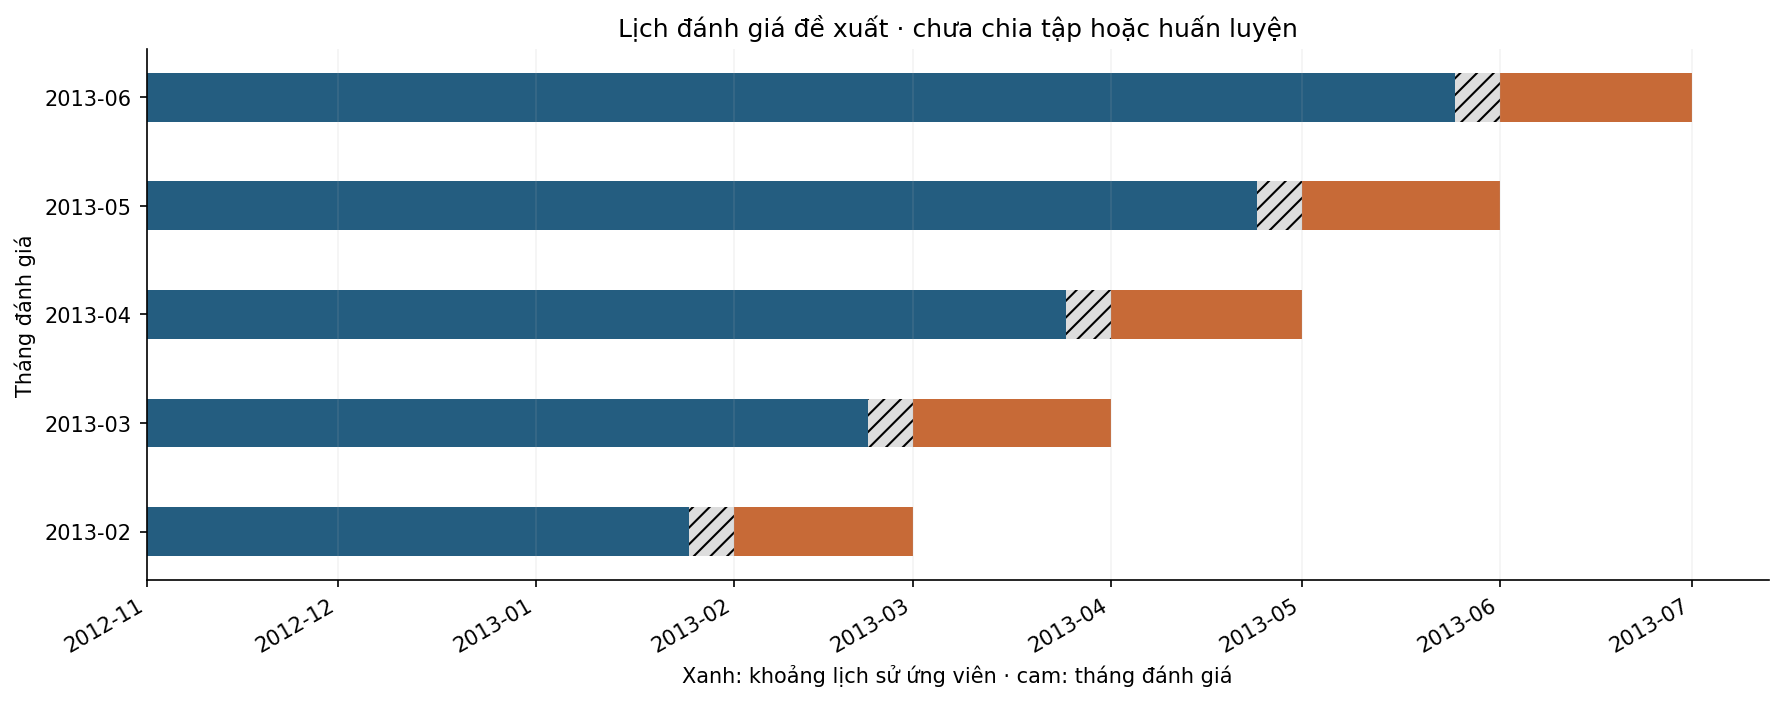

**Quan sát:** các cửa sổ đánh giá dùng thứ tự thời gian và lịch sử mở rộng.

**Phạm vi và cách đọc:** trục là timestamp search; vùng gạch chéo là khoảng đệm bảy ngày giả định. Chưa xác nhận độ trưởng thành nhãn; không fit nếu thiếu bằng chứng. Toàn bộ srch_id phải nằm trong một tập.

### Tiêu chí chấp nhận đặt trước

Các ngưỡng dưới đây là đề xuất nghiên cứu, chưa phải chuẩn phổ quát hoặc kết quả đo. Chốt trước khi huấn luyện. Độ bất định cần phản ánh cấu trúc phụ thuộc của dữ liệu.

**Điều kiện chấp nhận**

| Tiêu chí | Ngưỡng đề xuất | Cách diễn giải |
| --- | --- | --- |
| Khả dụng tại t0 · điều kiện chặn | 0 cột kết quả/đầu vào/cờ thiếu chưa được xác nhận tại t0; 0 nhóm giao tập | Chặn mọi mô hình nếu vi phạm; liên hệ EDA không thay được chứng cứ thời điểm |
| Thứ tự nhãn và hiệu chỉnh | 100% nhãn học/hiệu chỉnh sẵn có trước O; 100% điểm hiệu chỉnh là OOF theo thời gian | HOTEL cần snapshot; EXPEDIA cần timestamp kết quả hoặc quy tắc theo dõi đã xác nhận |
| Chuẩn xác suất tuyệt đối | \|Trung bình xác suất − tỷ lệ nhãn\| ≤2 điểm phần trăm; ECE 10 nhóm đồng số mẫu ≤3 điểm phần trăm | Đề xuất áp dụng từng tháng cuối và mẫu gộp; báo log loss, Brier, AP, ROC-AUC và biểu đồ độ tin cậy |
| Giá trị bổ sung của cây so với LR mạnh | Log loss giảm ≥1% tương đối; cận trên 95% của Δlog loss (cây − LR) <0 | So ghép cặp cùng mẫu và cùng nhánh; nếu không đạt thì chỉ dùng LR nếu LR qua chuẩn tuyệt đối |
| Độ bền | Báo riêng từng tháng, nhóm chính và kịch bản trùng/cơ chế hiển thị | Không có mô hình được chấp nhận nếu không ứng viên nào qua điều kiện bắt buộc |
| Nhánh xếp hạng | NDCG@5 tăng ≥2% tương đối so với xếp hạng bằng LR-booking; cận dưới 95% của ΔNDCG >0 | Macro theo search; gain=[0,1,5] dùng nhất quán. Báo riêng random_bool; không gọi điểm LambdaRank là propensity |

In [10]:
eda.show_section(report, 'design')

## Phụ lục — từ điển và bảng bổ sung

In [11]:
eda.show_section(report, 'appendix')

### Từ điển đủ 54 cột và schema train–test

Các ID được đọc thành số nhưng mang ý nghĩa phân loại. Nhóm đối thủ có **8 × 3 = 24 cột**, không phải 16. Bốn cột chỉ có ở train là position, click_bool, booking_bool, gross_bookings_usd. Sau khi tách bốn cột này, có 50 cột chung với test; đây là số cột schema, chưa phải số feature được phê duyệt sử dụng. Nếu srch_id chỉ làm khóa nhóm thì còn 49 cột ứng viên; prop_id vẫn cần quyết định cách dùng phù hợp ở giai đoạn sau.

**Schema và missing toàn bộ train**

| Cột gốc | Kiểu dữ liệu | Số thiếu toàn train | Tỷ lệ thiếu toàn train (%) | Có trong test | Ý nghĩa | Vai trò và lưu ý | Vai trò | unit | Miền giá trị và căn cứ |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| srch_id | int64 | 0 | 0 | 1 | ID lượt tìm kiếm | Khóa nhóm, không phải ID người dùng | định danh / khóa nhóm, không phải số liên tục | mã/nhãn phân loại, không có đơn vị vật lý | Khóa/mã; không in giá trị định danh cá nhân trong báo cáo |
| date_time | object | 0 | 0 | 1 | Thời điểm tìm kiếm | Thời gian, không giả định timezone không được công bố | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | ngày/giờ theo định dạng nguồn; timezone chưa xác minh | Toàn train: 2012-11-01 00:01:37–2013-06-30 23:58:24 |
| site_id | int64 | 0 | 0 | 1 | ID website/điểm bán Expedia | Phân loại | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | mã/nhãn phân loại, không có đơn vị vật lý | Toàn file: 34 mã khác nhau |
| visitor_location_country_id | int64 | 0 | 0 | 1 | ID quốc gia vị trí người tìm | Phân loại, không phải mã có thứ tự | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | mã/nhãn phân loại, không có đơn vị vật lý | Toàn file: 218 mã khác nhau |
| visitor_hist_starrating | float64 | 9,412,233 | 94.905 | 1 | Mức sao trung bình trong lịch sử khách | NA không đủ chứng minh khách mới/chưa đăng nhập | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | sao | Toàn file: [1, 5]; NA thống kê riêng |
| visitor_hist_adr_usd | float64 | 9,409,918 | 94.8817 | 1 | ADR lịch sử của khách, USD | Cần xác minh cửa sổ lịch sử và cách tính | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | USD | Toàn file: [0, 2768.93]; NA thống kê riêng |
| prop_country_id | int64 | 0 | 0 | 1 | ID quốc gia khách sạn | Phân loại | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | mã/nhãn phân loại, không có đơn vị vật lý | Toàn file: 172 mã khác nhau |
| prop_id | int64 | 0 | 0 | 1 | ID khách sạn | Thực thể có thể lặp qua searches; không phải số liên tục | định danh / khóa nhóm, không phải số liên tục | mã/nhãn phân loại, không có đơn vị vật lý | Khóa/mã; không in giá trị định danh cá nhân trong báo cáo |
| prop_starrating | int64 | 0 | 0 | 1 | Hạng sao khách sạn | 0 cần xác minh nghĩa; không tự xem là 0 sao chất lượng thấp | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | sao | Toàn file: [0, 5]; NA thống kê riêng |
| prop_review_score | float64 | 14,630 | 0.1475 | 1 | Điểm review khách sạn | 0 và NA là hai trường hợp cần phân biệt | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | điểm theo thang nguồn | Toàn file: [0, 5]; NA thống kê riêng |
| prop_brand_bool | int64 | 0 | 0 | 1 | Cờ thuộc thương hiệu/chuỗi | Nhị phân; cố định nhãn 0/1 khi vẽ | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | cờ 0/1 | Toàn file: 0, 1 |
| prop_location_score1 | float64 | 0 | 0 | 1 | Điểm vị trí thứ nhất | Thước đo do nguồn cung cấp | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | điểm theo thang nguồn | Toàn file: [0, 6.98]; NA thống kê riêng |
| prop_location_score2 | float64 | 2,178,380 | 21.9649 | 1 | Điểm vị trí thứ hai | Thước đo do nguồn cung cấp; có NA | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | điểm theo thang nguồn | Toàn file: [0, 1]; NA thống kê riêng |
| prop_log_historical_price | float64 | 0 | 0 | 1 | Log giá lịch sử khách sạn | Không tự khôi phục tiền khi chưa biết cơ số/cách tính | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | log giá; cơ số cần xác minh | Toàn file: [0, 6.21]; NA thống kê riêng |
| position | int64 | 0 | 0 | 0 | Vị trí hiển thị quan sát được | Có trong train, không có trong test; có ảnh hưởng vị trí | metadata hiển thị, chỉ có train | thứ hạng hiển thị | Toàn file: 40 mã khác nhau |
| price_usd | float64 | 0 | 0 | 1 | Giá hiển thị cho khách sạn trong search, USD | Cần xác minh đơn vị giá theo đêm/toàn kỳ; có đuôi cực lớn | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | USD; cần xác minh theo đêm/toàn kỳ | Toàn file: [0, 1.97263e+07]; NA thống kê riêng |
| promotion_flag | int64 | 0 | 0 | 1 | Cờ hiển thị khuyến mãi | Liên hệ quan sát không chứng minh tác động khuyến mãi | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | cờ 0/1 | Toàn file: 0, 1 |
| srch_destination_id | int64 | 0 | 0 | 1 | ID điểm đến tìm kiếm | Phân loại | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | mã/nhãn phân loại, không có đơn vị vật lý | Toàn file: 23715 mã khác nhau |
| srch_length_of_stay | int64 | 0 | 0 | 1 | Số đêm lưu trú tìm kiếm | Số đếm | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | đêm | Toàn file: [1, 59]; NA thống kê riêng |
| srch_booking_window | int64 | 0 | 0 | 1 | Số ngày từ search đến ngày đến | Đơn vị ngày | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | ngày | Toàn file: [0, 498]; NA thống kê riêng |
| srch_adults_count | int64 | 0 | 0 | 1 | Số người lớn trong search | Số đếm | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | người | Toàn file: [1, 9]; NA thống kê riêng |
| srch_children_count | int64 | 0 | 0 | 1 | Số trẻ em trong search | Số đếm | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | người | Toàn file: [0, 9]; NA thống kê riêng |
| srch_room_count | int64 | 0 | 0 | 1 | Số phòng trong search | Số đếm | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | phòng | Toàn file: [1, 8]; NA thống kê riêng |
| srch_saturday_night_bool | int64 | 0 | 0 | 1 | Cờ kỳ lưu trú có đêm thứ Bảy | Nhị phân | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | cờ 0/1 | Toàn file: 0, 1 |
| srch_query_affinity_score | float64 | 9,281,966 | 93.5915 | 1 | Điểm liên quan query–property do nguồn cung cấp | Cần xác minh cách sinh và tính sẵn có | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | điểm theo thang nguồn | Toàn file: [-326.567, -2.4941]; NA thống kê riêng |
| orig_destination_distance | float64 | 3,216,461 | 32.4321 | 1 | Khoảng cách nguồn–điểm đến theo nguồn | Đơn vị cần xác minh; không tự gán km | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | khoảng cách; đơn vị cần xác minh | Toàn file: [0.01, 11693]; NA thống kê riêng |
| random_bool | int64 | 0 | 0 | 1 | Cờ danh sách được sắp ngẫu nhiên | Phân tích ảnh hưởng vị trí; không tự suy ra exposure propensity | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | cờ 0/1 | Toàn file: 0, 1 |
| comp1_rate | float64 | 9,681,724 | 97.6223 | 1 | So sánh giá với đối thủ 1, mã phân loại | Không coi mã -1/0/1 là giá; xác minh hướng so sánh theo nguồn | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | mã/nhãn phân loại, không có đơn vị vật lý | Toàn file: -1.0, 0.0, 1.0 |
| comp1_inv | float64 | 9,663,097 | 97.4345 | 1 | So sánh tồn phòng với đối thủ 1 | Mã phân loại; NA không phải không có đối thủ | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | mã/nhãn phân loại, không có đơn vị vật lý | Toàn file: -1.0, 0.0, 1.0 |
| comp1_rate_percent_diff | float64 | 9,732,623 | 98.1356 | 1 | Chênh lệch giá phần trăm đối thủ 1 | NA có thể theo điều kiện sinh dữ liệu; xác minh mẫu số/hướng | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | % theo định nghĩa nguồn | Toàn file: [2, 30389]; NA thống kê riêng |
| comp2_rate | float64 | 5,876,897 | 59.2577 | 1 | So sánh giá với đối thủ 2, mã phân loại | Không coi mã -1/0/1 là giá; xác minh hướng so sánh theo nguồn | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | mã/nhãn phân loại, không có đơn vị vật lý | Toàn file: -1.0, 0.0, 1.0 |
| comp2_inv | float64 | 5,665,992 | 57.1311 | 1 | So sánh tồn phòng với đối thủ 2 | Mã phân loại; NA không phải không có đối thủ | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | mã/nhãn phân loại, không có đơn vị vật lý | Toàn file: -1.0, 0.0, 1.0 |
| comp2_rate_percent_diff | float64 | 8,807,683 | 88.8092 | 1 | Chênh lệch giá phần trăm đối thủ 2 | NA có thể theo điều kiện sinh dữ liệu; xác minh mẫu số/hướng | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | % theo định nghĩa nguồn | Toàn file: [2, 1.43992e+06]; NA thống kê riêng |
| comp3_rate | float64 | 6,858,257 | 69.1529 | 1 | So sánh giá với đối thủ 3, mã phân loại | Không coi mã -1/0/1 là giá; xác minh hướng so sánh theo nguồn | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | mã/nhãn phân loại, không có đơn vị vật lý | Toàn file: -1.0, 0.0, 1.0 |
| comp3_inv | float64 | 6,625,309 | 66.804 | 1 | So sánh tồn phòng với đối thủ 3 | Mã phân loại; NA không phải không có đối thủ | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | mã/nhãn phân loại, không có đơn vị vật lý | Toàn file: -1.0, 0.0, 1.0 |
| comp3_rate_percent_diff | float64 | 8,973,523 | 90.4814 | 1 | Chênh lệch giá phần trăm đối thủ 3 | NA có thể theo điều kiện sinh dữ liệu; xác minh mẫu số/hướng | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | % theo định nghĩa nguồn | Toàn file: [2, 199266]; NA thống kê riêng |
| comp4_rate | float64 | 9,297,431 | 93.7474 | 1 | So sánh giá với đối thủ 4, mã phân loại | Không coi mã -1/0/1 là giá; xác minh hướng so sánh theo nguồn | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | mã/nhãn phân loại, không có đơn vị vật lý | Toàn file: -1.0, 0.0, 1.0 |
| comp4_inv | float64 | 9,225,059 | 93.0177 | 1 | So sánh tồn phòng với đối thủ 4 | Mã phân loại; NA không phải không có đối thủ | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | mã/nhãn phân loại, không có đơn vị vật lý | Toàn file: -1.0, 0.0, 1.0 |
| comp4_rate_percent_diff | float64 | 9,653,317 | 97.3359 | 1 | Chênh lệch giá phần trăm đối thủ 4 | NA có thể theo điều kiện sinh dữ liệu; xác minh mẫu số/hướng | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | % theo định nghĩa nguồn | Toàn file: [2, 1.00158e+06]; NA thống kê riêng |
| comp5_rate | float64 | 5,473,236 | 55.1875 | 1 | So sánh giá với đối thủ 5, mã phân loại | Không coi mã -1/0/1 là giá; xác minh hướng so sánh theo nguồn | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | mã/nhãn phân loại, không có đơn vị vật lý | Toàn file: -1.0, 0.0, 1.0 |
| comp5_inv | float64 | 5,196,697 | 52.3991 | 1 | So sánh tồn phòng với đối thủ 5 | Mã phân loại; NA không phải không có đối thủ | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | mã/nhãn phân loại, không có đơn vị vật lý | Toàn file: -1.0, 0.0, 1.0 |
| comp5_rate_percent_diff | float64 | 8,236,524 | 83.0502 | 1 | Chênh lệch giá phần trăm đối thủ 5 | NA có thể theo điều kiện sinh dữ liệu; xác minh mẫu số/hướng | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | % theo định nghĩa nguồn | Toàn file: [2, 607561]; NA thống kê riêng |
| comp6_rate | float64 | 9,435,043 | 95.135 | 1 | So sánh giá với đối thủ 6, mã phân loại | Không coi mã -1/0/1 là giá; xác minh hướng so sánh theo nguồn | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | mã/nhãn phân loại, không có đơn vị vật lý | Toàn file: -1.0, 0.0, 1.0 |
| comp6_inv | float64 | 9,393,385 | 94.715 | 1 | So sánh tồn phòng với đối thủ 6 | Mã phân loại; NA không phải không có đối thủ | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | mã/nhãn phân loại, không có đơn vị vật lý | Toàn file: -1.0, 0.0, 1.0 |
| comp6_rate_percent_diff | float64 | 9,724,218 | 98.0508 | 1 | Chênh lệch giá phần trăm đối thủ 6 | NA có thể theo điều kiện sinh dữ liệu; xác minh mẫu số/hướng | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | % theo định nghĩa nguồn | Toàn file: [2, 1.12569e+06]; NA thống kê riêng |
| comp7_rate | float64 | 9,286,453 | 93.6368 | 1 | So sánh giá với đối thủ 7, mã phân loại | Không coi mã -1/0/1 là giá; xác minh hướng so sánh theo nguồn | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | mã/nhãn phân loại, không có đơn vị vật lý | Toàn file: -1.0, 0.0, 1.0 |
| comp7_inv | float64 | 9,204,355 | 92.8089 | 1 | So sánh tồn phòng với đối thủ 7 | Mã phân loại; NA không phải không có đối thủ | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | mã/nhãn phân loại, không có đơn vị vật lý | Toàn file: -1.0, 0.0, 1.0 |
| comp7_rate_percent_diff | float64 | 9,639,692 | 97.1985 | 1 | Chênh lệch giá phần trăm đối thủ 7 | NA có thể theo điều kiện sinh dữ liệu; xác minh mẫu số/hướng | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | % theo định nghĩa nguồn | Toàn file: [2, 30216]; NA thống kê riêng |
| comp8_rate | float64 | 6,098,487 | 61.492 | 1 | So sánh giá với đối thủ 8, mã phân loại | Không coi mã -1/0/1 là giá; xác minh hướng so sánh theo nguồn | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | mã/nhãn phân loại, không có đơn vị vật lý | Toàn file: -1.0, 0.0, 1.0 |
| comp8_inv | float64 | 5,957,142 | 60.0668 | 1 | So sánh tồn phòng với đối thủ 8 | Mã phân loại; NA không phải không có đối thủ | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | mã/nhãn phân loại, không có đơn vị vật lý | Toàn file: -1.0, 0.0, 1.0 |
| comp8_rate_percent_diff | float64 | 8,691,823 | 87.641 | 1 | Chênh lệch giá phần trăm đối thủ 8 | NA có thể theo điều kiện sinh dữ liệu; xác minh mẫu số/hướng | đầu vào ứng viên; chưa xác nhận khả dụng tại t0 | % theo định nghĩa nguồn | Toàn file: [2, 149400]; NA thống kê riêng |
| click_bool | int64 | 0 | 0 | 0 | Khách sạn có click trong search, 0/1 | Target/biến kết quả; không dùng click tương lai dự đoán trước click | đích | cờ 0/1 | Toàn file: 0, 1 |
| gross_bookings_usd | float64 | 9,640,938 | 97.2111 | 0 | Giá trị booking ghi nhận, USD | Kết quả sau booking; presence gần như tiết lộ nhãn | kết quả / nguy cơ rò rỉ đích | USD | Toàn file: [0, 167741]; NA thống kê riêng |
| booking_bool | int64 | 0 | 0 | 0 | Khách sạn được book trong search, 0/1 | Target | đích | cờ 0/1 | Toàn file: 0, 1 |

### Danh mục file, dung lượng và SHA-256

Phiên bản local được xác định bằng các giá trị dưới đây; không suy ngày tải từ ngày sửa file.

... (66 outputs left out)

### Truy vết tóm tắt điều hành

Số liệu tóm tắt được tạo từ cùng bảng/facts dùng xuất báo cáo. Metadata lưu giá trị gốc để đối chiếu, không chép tay số liệu.

**Phát hiện và nguồn trong báo cáo**

| STT | Phát hiện | Khóa mục bằng chứng |
| --- | --- | --- |
| 1 | **Đơn vị và quy mô:** 9,917,530 cặp thuộc 399,344 search; 54 cột train và 50 cột test. Không có user ID để chấm CRM. | quality |
| 2 | **Hai hành vi:** click 443,672 (4.47%), booking 276,593 (2.79%). Mẫu số là cặp search–property. | quality |
| 3 | **Quần thể có điều kiện:** 0 search hoàn toàn không click trong train; không suy CTR/CVR toàn website từ mẫu này. | quality |
| 4 | **Phụ thuộc trong search:** 0 search có cờ random không đồng nhất; đã tách trọng số theo dòng/search và phân tầng giá, sao theo cơ chế. | search_context |
| 5 | **Đầu vào và rò rỉ:** đủ 54 cột raw có quyết định; position, gross và hai nhãn bị chặn khỏi đầu vào trước hiển thị; srch_id chỉ làm khóa. | column_decisions |
| 6 | **Thiết kế đề xuất:** LR có tương tác so với LightGBM binary cho xác suất; LambdaRank là nhánh riêng. Giữ nguyên search qua các tập; khoảng đệm nhãn cần xác nhận, bootstrap theo search. | design |

## Tái lập và kiểm soát phạm vi

In [12]:
eda.show_section(report, 'reproducibility')

Chạy notebook theo thứ tự từ đầu, hoặc chạy `python scripts/build_descriptive_reports.py --dataset EXPEDIA` tại thư mục gốc. Script chỉ đọc CSV raw, viết báo cáo/biểu đồ và lưu notebook trong notebooks/; không sửa raw, không ghi data/processed, không gọi pipeline huấn luyện. Các thời điểm phân tích dùng Asia/Ho_Chi_Minh. SHA-256 ở danh mục file nhận diện nguồn; số dòng theo CSV parser được đối chiếu với data_lines của file chính. Ngày tải raw chưa được ghi nhận; không suy từ mtime/ctime. Expedia tính thống kê trên toàn bộ train, gồm quantile tuyến tính, skewness không chệch theo pandas và Spearman xếp hạng trung bình cho ties, loại NA theo từng cặp. Chỉ scatter (tối đa 4.000 điểm) và hình pattern missing (300 dòng) lấy mẫu hiển thị với numpy default_rng, seed=42; các bảng và heatmap tổng hợp dùng toàn bộ train. Cột raw được đệm tạm trên đĩa để giới hạn RAM và xóa sau khi xuất báo cáo; không tạo tập processed. Test chỉ là đối chiếu schema/chất lượng và các phân phối tổng hợp, không dùng tính thống kê train. Script thực thi các cell bằng IPython trong cùng tiến trình và lưu output thật vào notebook; không khởi tạo kernel mạng. Phụ thuộc dựng báo cáo gồm pandas, numpy, scipy, matplotlib, nbformat và IPython; có thể mở notebook bằng Jupyter để Run All.

Phần nghiên cứu bổ sung do scripts/hotel_expedia_research.py tạo từ cùng CSV. V tính từ bảng chéo K×2 không hiệu chỉnh; rank-biserial = 2U/(n1×n0)−1, với U của nhãn 1 và xử lý hòa hạng của SciPy. Không dùng kiểm định giả định các dòng độc lập để khẳng định ý nghĩa thống kê. Thống kê bổ sung Expedia dùng toàn bộ search và các bảng đếm toàn train. Các lịch chia tập chỉ là bảng quy mô, chưa sinh tập học hoặc dự đoán.

Chạy riêng: `python scripts/build_descriptive_reports.py --dataset EXPEDIA`. Cần package scripts/, pandas, numpy, scipy, matplotlib, nbformat và IPython cùng dữ liệu raw tương ứng. SHA-256 từng CSV ở phụ lục; ngày tải và phiên bản chưa được ghi nhận. Không suy ngày tải từ timestamp file.

**Môi trường thực thi**

| Thành phần | Giá trị |
| --- | --- |
| Python | 3.14.2 |
| pandas | 2.3.3 |
| numpy | 2.4.1 |
| matplotlib | 3.10.8 |
| Phương pháp | Thống kê mô tả, không mô hình |
| Chunk CSV lớn | 250000 |